# EDA: análisis exploratorio y limpieza

**Objetivo.** Conocer la base unificada `matches_sq.csv` (36,150 partidos de 9 ligas, 2014/15–2025/26), detectar problemas de calidad (nulos, tipos, outliers, duplicados), limpiar **de una sola vez y de forma definitiva** y exportar `matches_clean.csv`, y estudiar la relación de las variables clave con el resultado `FTR`.

**Criterio de limpieza.** Solo se elimina lo que no se puede usar y solo se corrige lo que se puede corregir sin inventar: las columnas con más del 20% de nulos se eliminan, **nada se imputa** (ni cuotas ni estadísticas de partido) y no se crean banderas de "ausente". Los nulos que quedan son los que la fuente no publica y cada tratamiento posterior se decide explícitamente en `02_feature.ipynb`.

In [73]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import seaborn as sns
import os
import missingno as msno
import ipywidgets as widgets

**Qué vamos a hacer.** Cargar la base unificada `matches_sq.csv`, generada por `scripts/download/process_data.py` (partidos de football-data.co.uk unidos con la calidad de plantilla derivada de los ratings FIFA/FC).

In [74]:
df = pd.read_csv("../data/matches_sq.csv")
df

/tmp/ipykernel_60578/1497358989.py:1: DtypeWarning: Columns (0: Time, 1: B365CH) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/matches_sq.csv")


,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,B365H,B365D,B365A,BWH,BWD,BWA,IWH,IWD,IWA,LBH,LBD,LBA,PSH,PSD,PSA,WHH,WHD,WHA,SJH,SJD,SJA,VCH,VCD,VCA,Bb1X2,BbMxH,BbAvH,BbMxD,BbAvD,BbMxA,BbAvA,BbOU,BbMx>2.5,BbAv>2.5,BbMx<2.5,BbAv<2.5,BbAH,BbAHh,BbMxAHH,BbAvAHH,BbMxAHA,BbAvAHA,PSCH,PSCD,PSCA,Season,HFKC,AFKC,Time,MaxH,MaxD,MaxA,AvgH,AvgD,AvgA,B365>2.5,B365<2.5,P>2.5,P<2.5,Max>2.5,Max<2.5,Avg>2.5,Avg<2.5,AHh,B365AHH,B365AHA,PAHH,PAHA,MaxAHH,MaxAHA,AvgAHH,AvgAHA,B365CH,B365CD,B365CA,BWCH,BWCD,BWCA,IWCH,IWCD,IWCA,WHCH,WHCD,WHCA,VCCH,VCCD,VCCA,MaxCH,MaxCD,MaxCA,AvgCH,AvgCD,AvgCA,B365C>2.5,B365C<2.5,PC>2.5,PC<2.5,MaxC>2.5,MaxC<2.5,AvgC>2.5,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,Unnamed: 105,BFH,BFD,BFA,1XBH,1XBD,1XBA,BFEH,BFED,BFEA,BFE>2.5,BFE<2.5,BFEAHH,BFEAHA,BFCH,BFCD,BFCA,1XBCH,1XBCD,1XBCA,BFECH,BFECD,BFECA,BFEC>2.5,BFEC<2.5,BFECAHH,BFECAHA,Unnamed: 119,Unnamed: 120,BFDH,BFDD,BFDA,BMGMH,BMGMD,BMGMA,BVH,BVD,BVA,CLH,CLD,CLA,BFDCH,BFDCD,BFDCA,BMGMCH,BMGMCD,BMGMCA,BVCH,BVCD,BVCA,CLCH,CLCD,CLCA,LBCH,LBCD,LBCA,HomeTeam_sq_n_players,HomeTeam_sq_overall_mean,HomeTeam_sq_overall_max,HomeTeam_sq_top11_mean,HomeTeam_sq_top15_mean,HomeTeam_sq_gk_mean,HomeTeam_sq_gk_top_mean,HomeTeam_sq_gk_top3_mean,HomeTeam_sq_def_mean,HomeTeam_sq_def_top_mean,HomeTeam_sq_def_top3_mean,HomeTeam_sq_mid_mean,HomeTeam_sq_mid_top_mean,HomeTeam_sq_mid_top3_mean,HomeTeam_sq_att_mean,HomeTeam_sq_att_top_mean,HomeTeam_sq_att_top3_mean,HomeTeam_sq_mapped,AwayTeam_sq_n_players,AwayTeam_sq_overall_mean,AwayTeam_sq_overall_max,AwayTeam_sq_top11_mean,AwayTeam_sq_top15_mean,AwayTeam_sq_gk_mean,AwayTeam_sq_gk_top_mean,AwayTeam_sq_gk_top3_mean,AwayTeam_sq_def_mean,AwayTeam_sq_def_top_mean,AwayTeam_sq_def_top3_mean,AwayTeam_sq_mid_mean,AwayTeam_sq_mid_top_mean,AwayTeam_sq_mid_top3_mean,AwayTeam_sq_att_mean,AwayTeam_sq_att_top_mean,AwayTeam_sq_att_top3_mean,AwayTeam_sq_mapped
0,E0,16/08/14,Arsenal,Crystal Palace,2,1,H,1.0,1.0,D,J Moss,14.0,4.0,6.0,2.0,13.0,19.0,9.0,3.0,2.0,2.0,0.0,1.0,1.25,6.50,15.00,1.25,5.50,12.00,1.30,5.0,9.0,1.25,6.00,13.00,1.26,6.45,14.01,1.25,5.5,12.0,1.25,5.75,12.00,1.25,6.25,10.50,50.0,1.30,1.25,6.70,5.96,16.00,12.43,48.0,1.77,1.72,2.26,2.10,24.0,-1.50,1.81,1.78,2.20,2.10,1.29,5.90,12.75,1415,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33.0,74.181818,86.0,82.090909,81.200000,66.600000,80.0,73.333333,73.250000,83.0,81.333333,77.333333,86.0,84.333333,73.800000,84.0,80.333333,1,33.0,69.424242,75.0,74.000000,73.466667,67.750000,75.0,70.333333,69.200000,74.0,74.000000,69.466667,75.0,75.000000,71.500000,73.0,72.000000,1
1,E0,16/08/14,Leicester,Everton,2,2,D,1.0,2.0,A,M Jones,11.0,13.0,3.0,3.0,16.0,10.0,3.0,6.0,1.0,1.0,0.0,0.0,3.20,3.40,2.40,2.90,3.20,2.40,2.90,3.3,2.3,3.25,3.40,2.25,3.14,3.38,2.46,3.10,3.1,2.4,3.00,3.30,2.38,3.20,3.40,2.40,50.0,3.30,3.06,3.45,3.32,2.42,2.36,48.0,2.10,2.00,1.90,1.80,22.0,0.25,1.88,1.85,2.10,2.02,3.11,3.40,2.47,1415,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33.0,66.454545,78.0,72.090909,71.266667,65.666667,74.0,65.666667,67.500000,73.0,72.000000,67.818182,78.0,73.000000,63.888889

**Hallazgo.** La base tiene **36,150 filas** (partidos) y **225 columnas**: 9 ligas × 12 temporadas (2014/15–2025/26). Pandas avisa de tipos mixtos en `Referee`, `Time` y `B365CH`.

**Siguiente.** Revisar tipos y nulos con `info()`.

In [75]:
pd.set_option('display.max_info_columns', 300)
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_columns', 300)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 40)
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 36150 entries, 0 to 36149
Data columns (total 225 columns):
 #    Column                     Non-Null Count  Dtype  
---   ------                     --------------  -----  
 0    Div                        36150 non-null  str    
 1    Date                       36150 non-null  str    
 2    HomeTeam                   36150 non-null  str    
 3    AwayTeam                   36150 non-null  str    
 4    FTHG                       36150 non-null  int64  
 5    FTAG                       36150 non-null  int64  
 6    FTR                        36150 non-null  str    
 7    HTHG                       36111 non-null  float64
 8    HTAG                       36111 non-null  float64
 9    HTR                        36111 non-null  str    
 10   Referee                    4560 non-null   str    
 11   HS                         32637 non-null  float64
 12   AS                         32637 non-null  float64
 13   HST                        32637 non-nul

**Hallazgo.**

- Hay **159 columnas de cuotas**; ninguna está completa en toda la serie, porque cada casa empezó o dejó de publicar en temporadas distintas.
- `B365CH` es de tipo texto: contiene un valor no numérico (`#`, un error de captura en 2022/23). La columna se elimina más adelante por exceso de nulos.
- Las columnas `Unnamed: 105`, `119` y `120` están 100% vacías (artefactos de la concatenación).

**Siguiente.** Resumen estadístico de las variables numéricas.

In [76]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
FTHG,36150.0,1.56,1.31,0.00,1.00,1.00,2.00,10.00
FTAG,36150.0,1.24,1.17,0.00,0.00,1.00,2.00,13.00
HTHG,36111.0,0.69,0.84,0.00,0.00,0.00,1.00,6.00
HTAG,36111.0,0.55,0.75,0.00,0.00,0.00,1.00,7.00
HS,32637.0,13.55,5.35,0.00,10.00,13.00,17.00,46.00
AS,32637.0,11.12,4.75,0.00,8.00,11.00,14.00,45.00
HST,32637.0,4.87,2.61,0.00,3.00,5.00,6.00,20.00
AST,32637.0,4.01,2.36,0.00,2.00,4.00,5.00,23.00
HF,32157.0,12.45,4.14,0.00,10.00,12.00,15.00,33.00
AF,32157.0,12.71,4.19,0.00,10.00,12.00,15.00,34.00


**Hallazgo.** Goles del local 1.56 vs visitante 1.24 por partido (ventaja de localía ≈ 0.32 goles). Tiros, córners, faltas y tarjetas tienen ≈ 3,500–4,000 nulos (≈ 10%): esos son los partidos de ligas que no publican estadísticas antes de 2017/18 (el patrón exacto se detalla en la limpieza, más abajo).

**Siguiente.** Resumen de las variables categóricas.

In [77]:
df.describe(include="object")

/tmp/ipykernel_60578/702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Div,Date,HomeTeam,AwayTeam,FTR,HTR,Referee,Time,B365CH
count,36150,36150,36150,36150,36150,36111,4560,21230,21200.00
unique,9,2634,296,296,3,3,53,47,259.00
top,E0,22/12/2018,Arsenal,Crystal Palace,H,D,A Taylor,20:00,2.05
freq,4560,53,228,228,16044,14679,356,2033,432.00


**Hallazgo.** Hay **296 equipos** y 2,634 fechas distintas. `Referee` tiene solo 4,560 valores (≈ 13%, todos de la Premier League) y `Time` 21,230 (≈ 59%, solo desde 2019/20).

**Decisión.** Se tratan en la limpieza (más abajo).

Como se observa en información del dataframe, vemos que existen atributos con los nombres `Unnamed: 105`, `Unnamed: 119`, `Unnamed: 120` en los cuales sus respectivas columnas estan vacias, por lo cual vamos a eliminarlas.

In [78]:
df_clean = df.copy()
df_clean = df_clean.drop(columns=["Unnamed: 105", "Unnamed: 119", "Unnamed: 120"])
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 36150 entries, 0 to 36149
Data columns (total 222 columns):
 #    Column                     Non-Null Count  Dtype  
---   ------                     --------------  -----  
 0    Div                        36150 non-null  str    
 1    Date                       36150 non-null  str    
 2    HomeTeam                   36150 non-null  str    
 3    AwayTeam                   36150 non-null  str    
 4    FTHG                       36150 non-null  int64  
 5    FTAG                       36150 non-null  int64  
 6    FTR                        36150 non-null  str    
 7    HTHG                       36111 non-null  float64
 8    HTAG                       36111 non-null  float64
 9    HTR                        36111 non-null  str    
 10   Referee                    4560 non-null   str    
 11   HS                         32637 non-null  float64
 12   AS                         32637 non-null  float64
 13   HST                        32637 non-nul

Como vemos tenemos muchos atributos de cuotas por datos, entonces vamos a revisar como se distribuyen estas variables

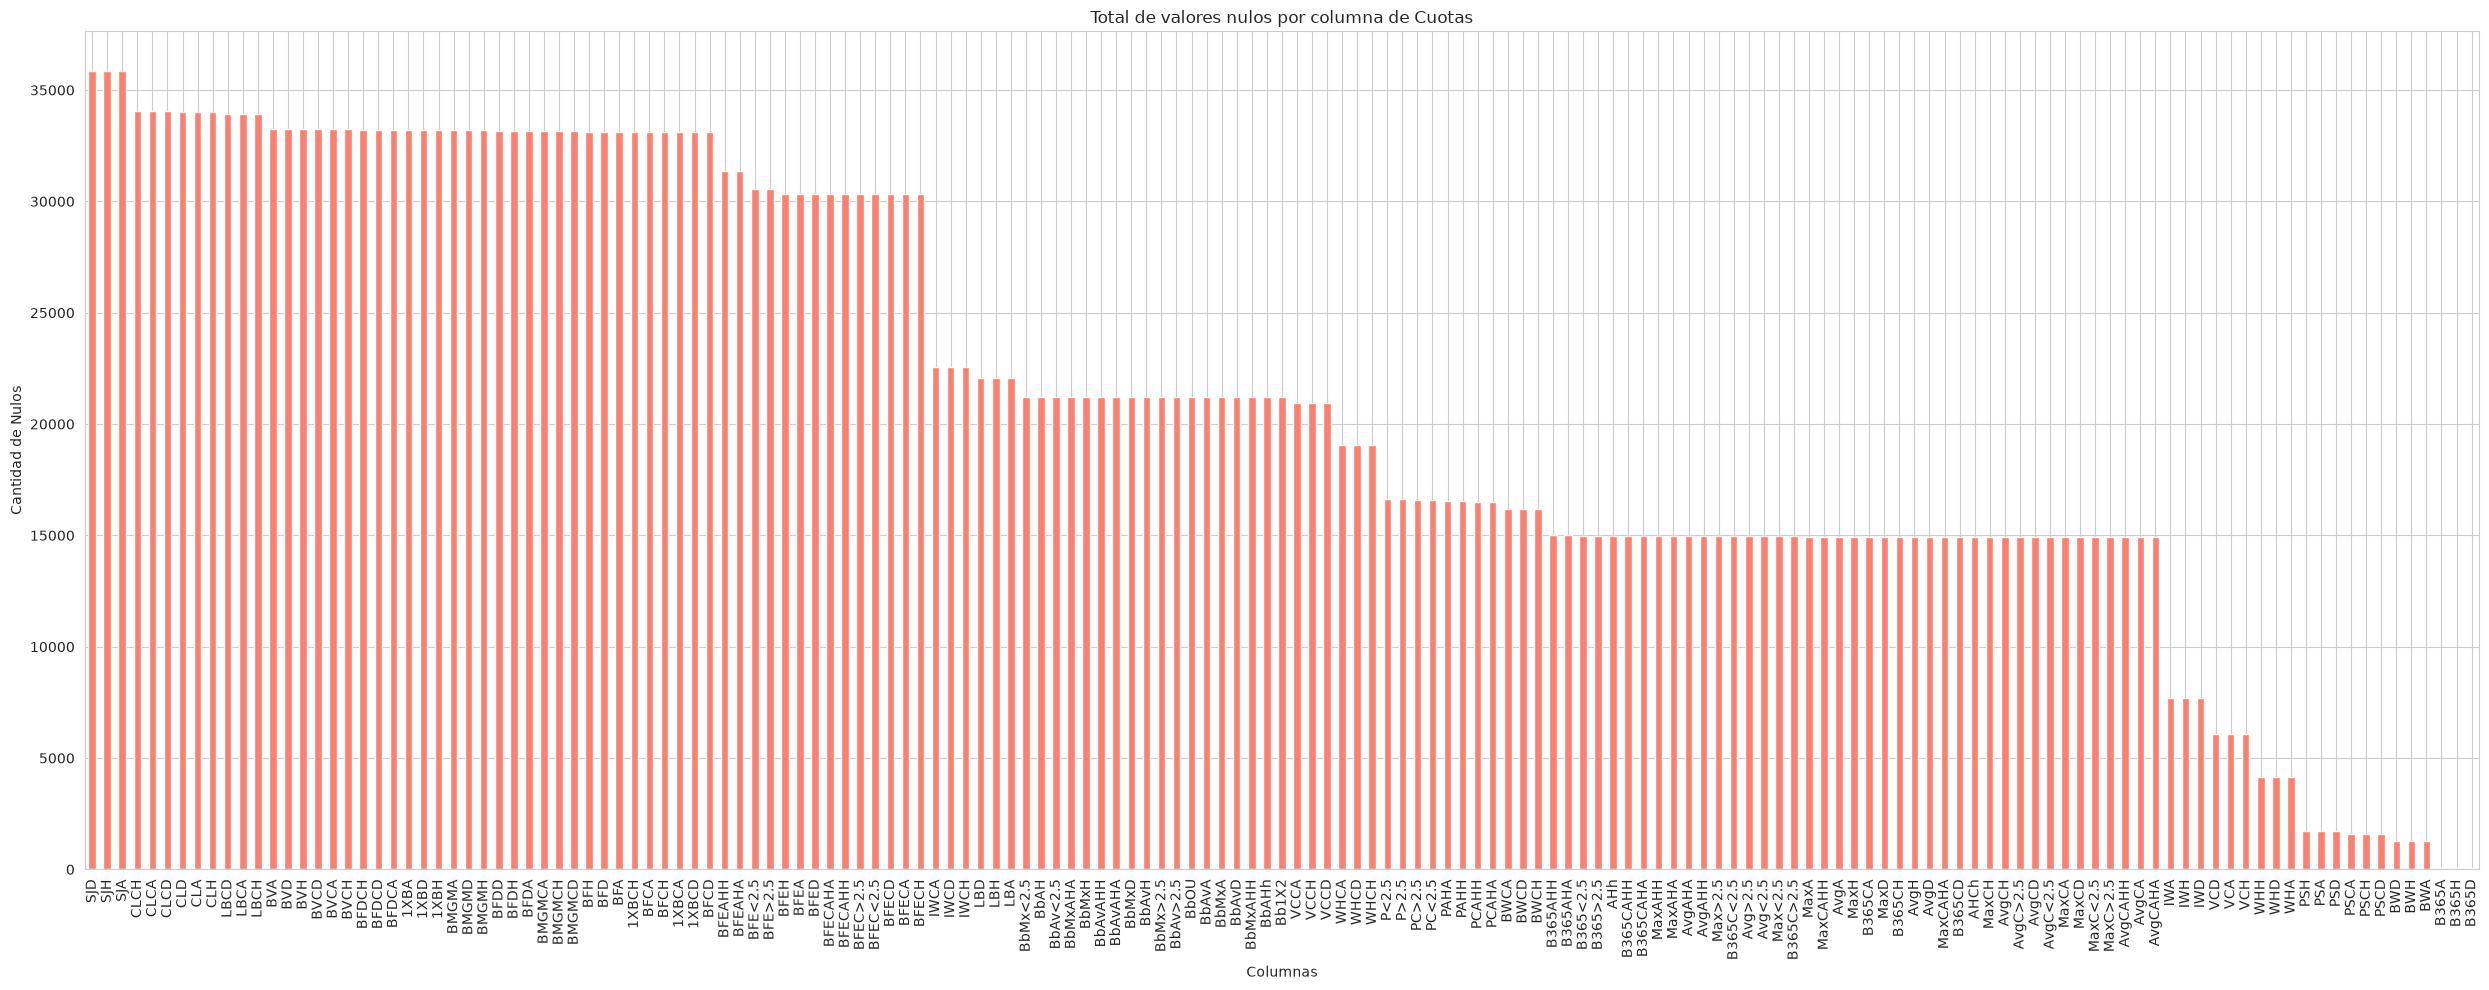

In [79]:
CUOTAS = ['B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA', 'LBH', 'LBD', 'LBA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA',
          'VCH', 'VCD', 'VCA', 'Bb1X2', 'BbMxH', 'BbAvH', 'BbMxD', 'BbAvD', 'BbMxA', 'BbAvA', 'BbOU', 'BbMx>2.5', 'BbAv>2.5', 'BbMx<2.5',
          'BbAv<2.5', 'BbAH', 'BbAHh', 'BbMxAHH', 'BbAvAHH', 'BbMxAHA', 'BbAvAHA', 'PSCH', 'PSCD', 'PSCA', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 
          'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH',
          'PAHA', 'MaxAHH','MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'WHCH', 'WHCD',
          'WHCA', 'VCCH', 'VCCD', 'VCCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC>2.5', 
          'MaxC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'AHCh', 'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA', 'AvgCAHH', 'AvgCAHA', 'BFH', 'BFD', 
          'BFA', '1XBH', '1XBD', '1XBA', 'BFEH', 'BFED', 'BFEA', 'BFE>2.5', 'BFE<2.5', 'BFEAHH', 'BFEAHA', 'BFCH', 'BFCD', 'BFCA', '1XBCH', '1XBCD', '1XBCA', 
          'BFECH', 'BFECD', 'BFECA', 'BFEC>2.5', 'BFEC<2.5', 'BFECAHH', 'BFECAHA', 'BFDH', 'BFDD', 'BFDA', 'BMGMH', 'BMGMD', 'BMGMA', 'BVH', 'BVD', 'BVA', 
          'CLH', 'CLD', 'CLA', 'BFDCH', 'BFDCD', 'BFDCA', 'BMGMCH', 'BMGMCD', 'BMGMCA', 'BVCH', 'BVCD', 'BVCA', 'CLCH', 'CLCD', 'CLCA', 'LBCH', 'LBCD', 'LBCA', 'SJH', 'SJD', 'SJA']
          
nulos_por_columna = df_clean[CUOTAS].isnull().sum()

nulos_por_columna = nulos_por_columna[nulos_por_columna > 0]

plt.figure(figsize=(25, 10))
nulos_por_columna.sort_values(ascending=False).plot(kind='bar', color='salmon')

plt.title('Total de valores nulos por columna de Cuotas')
plt.ylabel('Cantidad de Nulos')
plt.xlabel('Columnas')
plt.xticks(rotation=90) # Rota las etiquetas para que se puedan leer
plt.tight_layout()
plt.show()

**Qué vamos a hacer.** Clasificar las 159 columnas de cuotas por su proporción de nulos y aplicar **una sola regla**: las que superan el **20% de nulos** (7,230 filas) se eliminan; las demás se **conservan tal como se observaron, sin imputar**.

**Por qué.** Las columnas con muchos nulos pertenecen a casas o mercados que solo se publicaron en ciertas temporadas; imputarlas fabricaría un precio que ninguna casa publicó. Tampoco se crean banderas de "cuota ausente": esa ausencia depende de la temporada en que la fuente dejó de publicar y delataría el año, no el partido. Para las que sí se conservan, un NaN significa "esa casa no publicó este partido", y se trata en el feature engineering construyendo el mercado solo con las casas que sí publicaron.

In [80]:
len(CUOTAS)

159

**Hallazgo.** Hay 159 columnas de cuotas en la base. Con umbral del 40% de 36,150 filas (14,460), se descartarán las que lo superen.

In [81]:
n_total = len(df_clean)
frac = nulos_por_columna / n_total
b40 = [c for c in nulos_por_columna.index if frac[c] > 0.40]
b20 = [c for c in nulos_por_columna.index if 0.20 < frac[c] <= 0.40]
for c in b40 + b20:
    df_clean = df_clean.drop(columns=[c]); CUOTAS.remove(c)
print(f"eliminadas por > 40% de nulos: {len(b40)} | eliminadas por 20-40%: {len(b20)} {b20} | cuotas restantes: {len(CUOTAS)}")
print('nulos de las cuotas restantes:', {c: int(df_clean[c].isnull().sum()) for c in CUOTAS if df_clean[c].isnull().sum() > 0})

eliminadas por > 40% de nulos: 138 | eliminadas por 20-40%: 3 ['IWH', 'IWD', 'IWA'] | cuotas restantes: 18
nulos de las cuotas restantes: {'B365H': 58, 'B365D': 58, 'B365A': 58, 'BWH': 1263, 'BWD': 1263, 'BWA': 1263, 'PSH': 1703, 'PSD': 1703, 'PSA': 1703, 'WHH': 4152, 'WHD': 4152, 'WHA': 4152, 'VCH': 6090, 'VCD': 6090, 'VCA': 6090, 'PSCH': 1603, 'PSCD': 1603, 'PSCA': 1603}


**Qué encontramos.** Se eliminaron **141 columnas de cuotas**: 138 con más del 40% de nulos (casas secundarias y mercados de cierre, hándicap asiático y over/under con cobertura parcial) y 3 con 21.3% (`IWH`, `IWD`, `IWA`: Interwetten dejó de publicar en 2023/24).

**Qué significa para nuestro caso.** Una sola regla (más del 20% de nulos se elimina) y ninguna bandera: así no queda en el dataset ninguna variable que solo indique el año. Las cuotas que sobreviven son las de las casas que publicaron casi siempre.

**Decisión.** Eliminar sin imputar ni crear banderas.

In [82]:
len(CUOTAS)

18

**Qué encontramos.** Quedan **18 columnas de cuotas** (6 casas × 3 resultados) con entre 58 nulos (`B365`) y 6,090 (`VC`, 16.8%).

**Qué vamos a hacer.** Comprobar que los nulos que quedan en las 18 columnas de cuotas (6 casas × 3 resultados) son **estructurales** (una casa que no publicó) y medir en cuántos partidos faltan **todas** las casas que usaremos para el consenso de mercado.

**Por qué.** Si faltaran al azar sería un problema de calidad del dato; si faltan por casa y temporada, la decisión correcta es no imputar y construir el mercado con las casas disponibles. El KNN imputaba cada columna por separado y fabricaba tríos incoherentes (probabilidades que no suman 1) cuando faltaban todas las casas de un partido.

In [83]:
casas = {'B365': ['B365H', 'B365D', 'B365A'], 'BW': ['BWH', 'BWD', 'BWA'], 'PS (Pinnacle)': ['PSH', 'PSD', 'PSA'], 'WH': ['WHH', 'WHD', 'WHA'], 'VC': ['VCH', 'VCD', 'VCA'], 'PSC (cierre Pinnacle)': ['PSCH', 'PSCD', 'PSCA']}
sin = pd.DataFrame({k: df_clean[v].isnull().any(axis=1).groupby(df_clean['Season']).mean() * 100 for k, v in casas.items()}).T
sin['TOTAL'] = [df_clean[v].isnull().any(axis=1).mean() * 100 for v in casas.values()]
print('% de partidos en que la casa no publico las tres cuotas, por temporada:'); print(sin.round(1).to_string())
casas_apertura = ['B365', 'BW', 'PS (Pinnacle)', 'WH']
ninguna = np.logical_and.reduce([df_clean[casas[k]].isnull().any(axis=1) for k in casas_apertura])
print('\npartidos sin cuotas de apertura de ninguna de las 4 casas (B365, BW, Pinnacle, WH):', int(ninguna.sum()), '| por liga-temporada:', df_clean[ninguna].groupby(['Div', 'Season']).size().to_dict())
n_casas = sum((~df_clean[casas[k]].isnull().any(axis=1)).astype(int) for k in casas_apertura)
print('casas de apertura disponibles por partido: minimo', int(n_casas.min()), '| mediana', int(n_casas.median()), '| media', round(float(n_casas.mean()), 2))

% de partidos en que la casa no publico las tres cuotas, por temporada:
Season                 1415  1516  1617  1718  1819  1920  2021  2122  2223  2324   2425   2526  TOTAL
B365                    0.0   0.1   0.0   0.1   0.0   0.0   0.3   0.1   1.1   0.0    0.1    0.1    0.2
BW                      0.1   0.0   0.0   0.0   0.0   0.0   0.3   0.2   1.0   2.2   38.0    0.1    3.5
PS (Pinnacle)           0.5   0.1   0.8   1.3   0.5   0.2   0.2   0.1   1.0   0.1    0.1   52.2    4.7
WH                      0.3   0.0   0.1   0.1   0.1   0.0   0.4   0.6   7.2   4.2   25.4  100.0   11.5
VC                      0.0   0.1   0.0   0.1   0.0   0.1   0.3   0.4   1.7   0.2  100.0  100.0   16.8
PSC (cierre Pinnacle)   0.1   0.0   0.0   0.3   0.0   0.0   0.0   0.0   0.9   0.0    0.0   52.2    4.4

partidos sin cuotas de apertura de ninguna de las 4 casas (B365, BW, Pinnacle, WH): 31 | por liga-temporada: {('I1', 2021): 1, ('I1', 2122): 1, ('T1', 2223): 29}
casas de apertura disponibles por partido: m

**Qué encontramos.**

- Los nulos de las cuotas **son estructurales**: dependen de la casa y la temporada. Bet365 falta en 0.2% de los partidos; Pinnacle en 4.7% (pero en **52% de 2025/26**); William Hill en 11.5% (**100% en 2025/26** y 25% en 2024/25); Vcbet en 16.8% (**100% desde 2024/25**) y BetWin en 38% de 2024/25.
- Solo hay **31 partidos sin cuotas de apertura de ninguna de las cuatro casas** (B365, BW, Pinnacle, WH): 29 de la Süper Lig 2022/23 y 2 de la Serie A.
- La mediana es de 4 casas por partido, con 3.8 de media.

**Qué significa para nuestro caso.** No se imputa: imputar fabricaría un precio inexistente (y, como los nulos se concentran en las últimas temporadas, introduciría un cambio artificial justo en los datos más recientes). El mercado se construirá con las casas que sí publicaron cada partido, y los 31 partidos sin ninguna cuota quedarán fuera del modelado (siguen aportando historial a sus equipos). Además, que Pinnacle falte en la mitad de 2025/26 es una limitación que habrá que recordar al evaluar el modelo final.

**Decisión.** Conservar las cuotas observadas con NaN.

La variable `Time` (hora de inicio) solo existe desde la temporada 2019/20: es nula en 2014/15–2018/19 (~41% del dataset). Su ausencia no es aleatoria sino estructural (depende de la temporada), así que imputarla con `KNNImputer` solo fabricaría horas sintéticas. La **descartamos** y no se crea `Time_hora`.

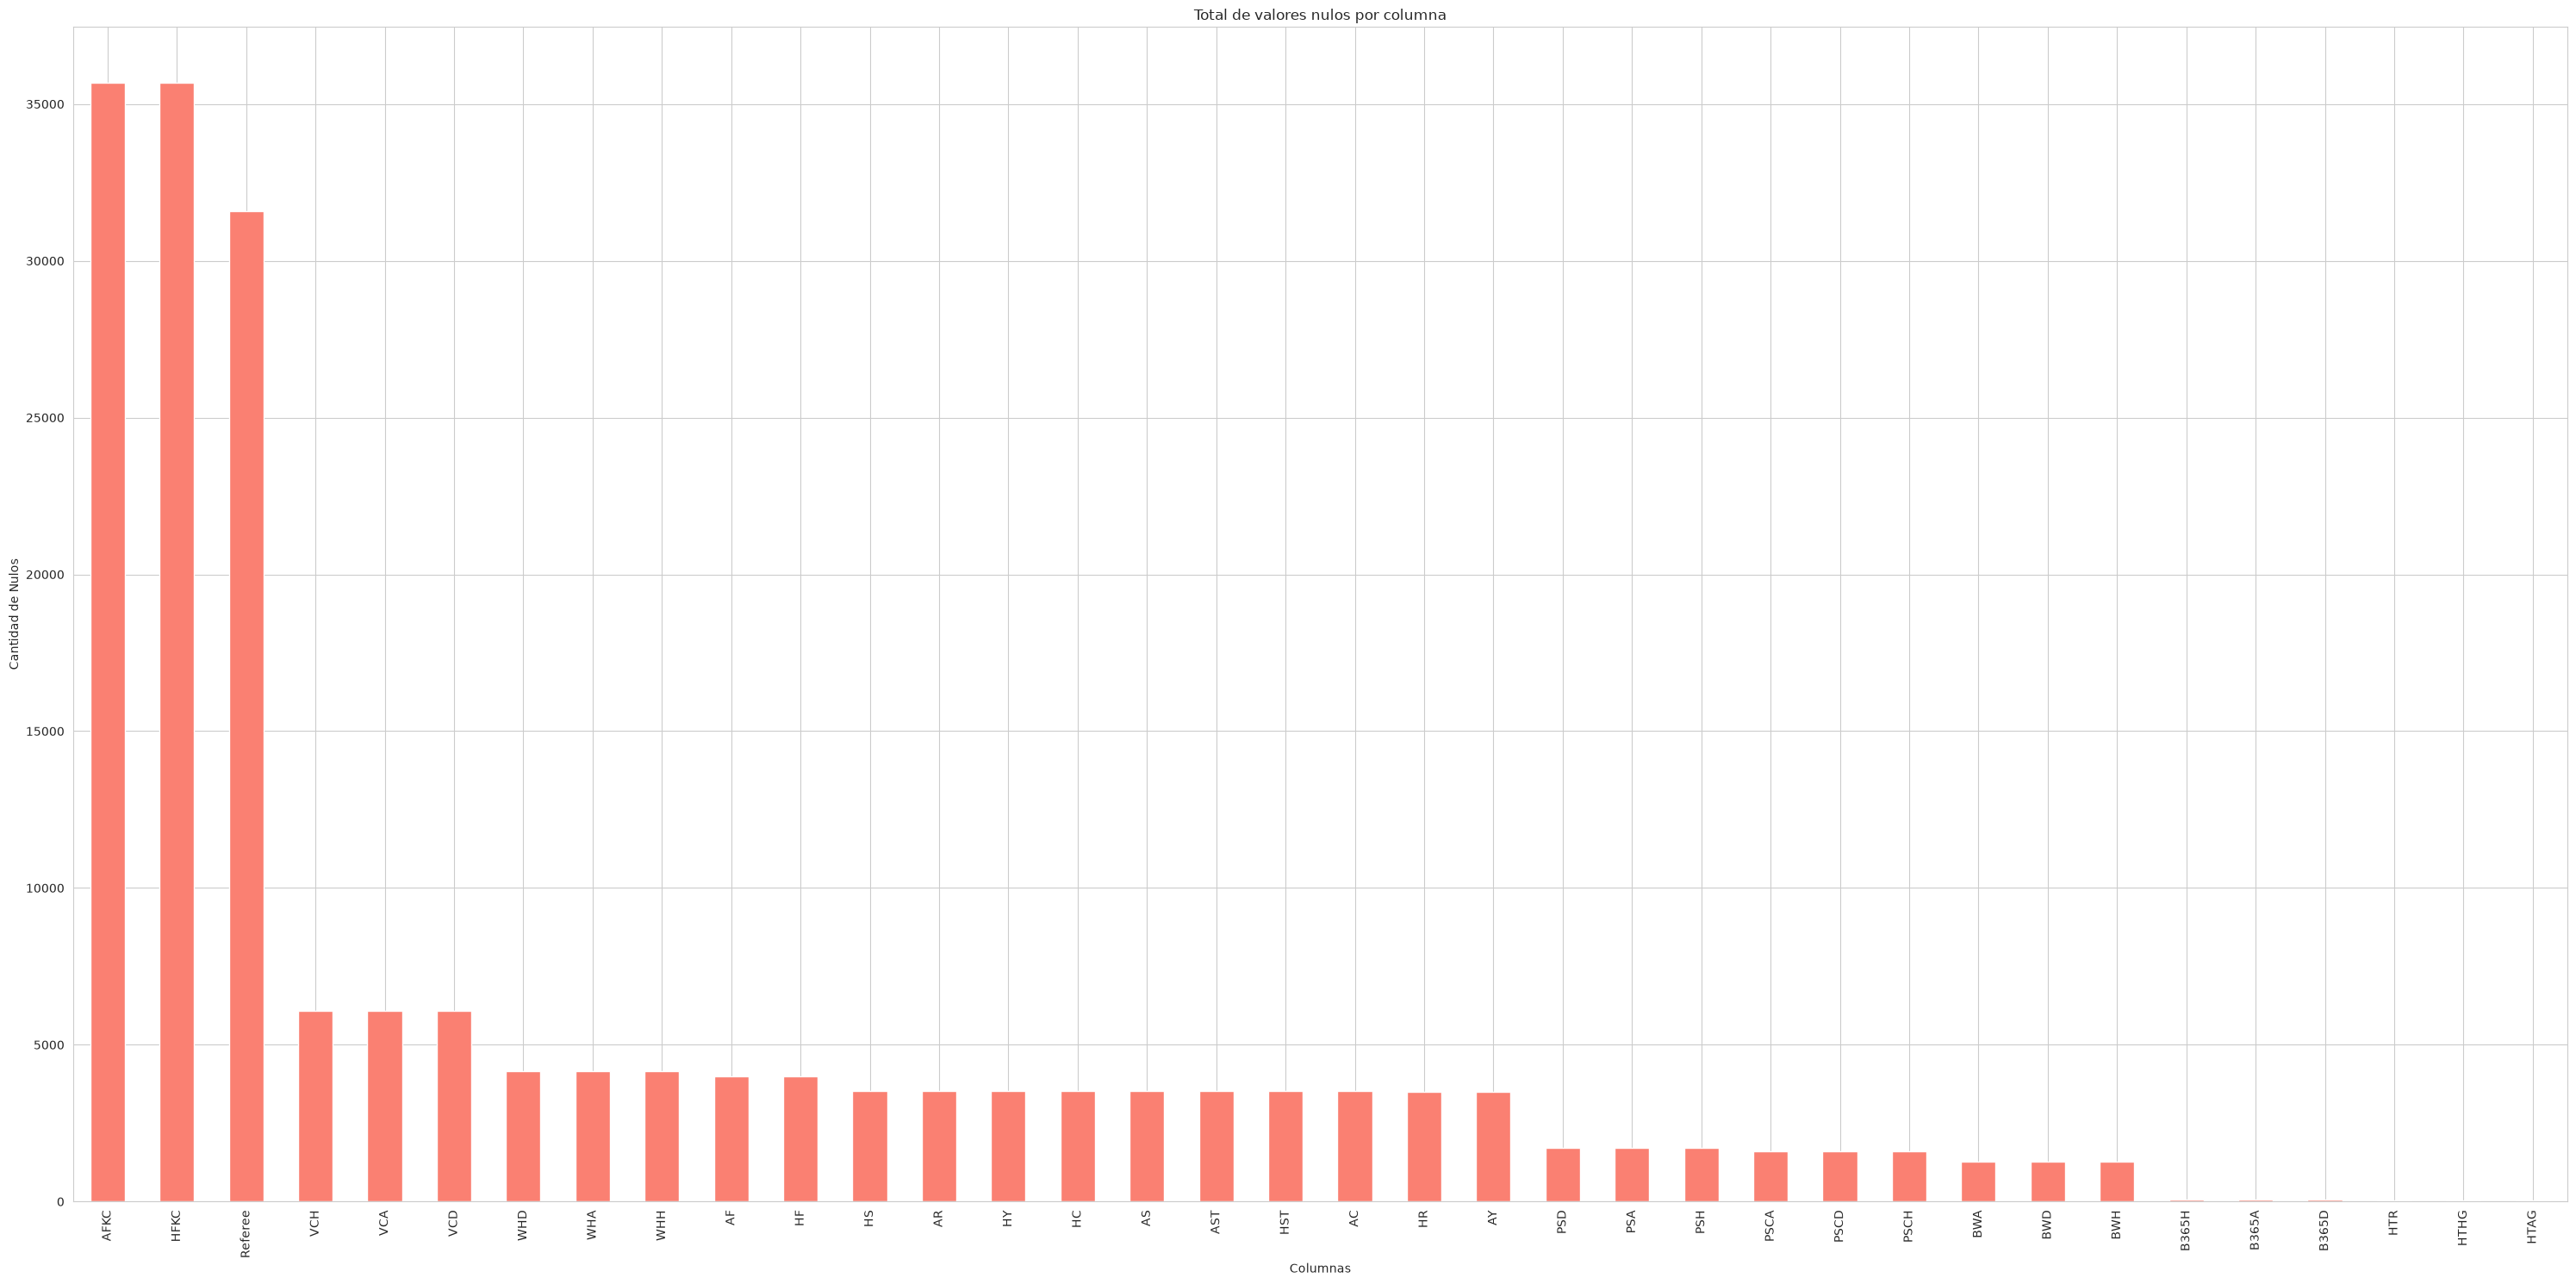

In [84]:
df_clean = df_clean.drop(columns=["Time"])
faltantes = []
for col in df_clean.columns:
    if df_clean[col].isnull().sum() > 0:
        faltantes.append(col)

col_faltantes = df_clean[faltantes].isnull().sum()

plt.figure(figsize=(30, 15))
col_faltantes.sort_values(ascending=False).plot(kind='bar', color='salmon')

plt.title('Total de valores nulos por columna')
plt.ylabel('Cantidad de Nulos')
plt.xlabel('Columnas')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


**Hallazgo.** Tras eliminar `Time`, las columnas con más nulos son `HFKC` y `AFKC` (35,672 cada una, 98.7%) y `Referee` (31,590, 87.4%). El árbitro solo lo publica la Premier League (E0).

**Decisión.** Eliminar las tres columnas: superan ampliamente el 40%.

In [85]:
df_clean = df_clean.drop(columns=['HFKC', 'AFKC', 'Referee'])
col_faltantes = col_faltantes.drop(['HFKC', 'AFKC', 'Referee'])

**Hallazgo.** `HFKC`, `AFKC` y `Referee` eliminadas.

Los nulos restantes son de dos tipos y reciben un tratamiento distinto:

- **Estadísticas de partido** (`HS`, `HST`, `HC`, `HF`, `HY`, `HR` y sus pares del visitante): son datos *post-partido* que solo alimentan el historial de forma de partidos posteriores. Su ausencia es **estructural** (la fuente no las publica para ciertas ligas y temporadas), así que **no se imputan**: se documenta el patrón y se conservan como NaN.
- **Calidad de plantilla** (`*_sq_*`): es información *pre-partido*. Se imputa con la media de su liga y temporada; **nunca** con columnas del propio partido (en versiones anteriores se imputaba junto a las estadísticas post-partido, lo que filtraba información del resultado hacia una variable pre-partido).

In [86]:
sq_all = [col for col in df_clean.columns if '_sq_' in col]
assert df_clean[sq_all].isnull().sum().sum() == 0, 'la plantilla deberia estar completa'
print('columnas de plantilla:', len(sq_all), '| nulos:', 0)

# patron de nulos de las estadisticas de partido: por liga y temporada
STATS = ['HS', 'AS', 'HST', 'AST', 'HC', 'AC', 'HF', 'AF', 'HY', 'AY', 'HR', 'AR']
nan_row = df_clean[STATS].isnull().any(axis=1)
tabla = df_clean.assign(nan=nan_row).groupby(['Div', 'Season'])['nan'].sum().unstack(fill_value=0)
tabla = tabla[tabla.sum(axis=1) > 0]; tabla = tabla.loc[:, tabla.sum() > 0]
print(f"\npartidos con alguna estadistica de partido en NaN: {int(nan_row.sum())} ({nan_row.mean():.1%})")
print('Partidos con NaN por liga y temporada (solo filas y columnas con NaN):'); print(tabla.to_string())
faltan_det = df_clean[STATS].isnull().mean().round(3)
print('\n% de nulos por columna de estadistica:', faltan_det.to_dict())

columnas de plantilla: 36 | nulos: 0

partidos con alguna estadistica de partido en NaN: 3995 (11.1%)
Partidos con NaN por liga y temporada (solo filas y columnas con NaN):
Season  1415  1516  1617  1718  1819  2122  2223  2324  2425
Div                                                         
B1       240   240   240   240   240     3     2     0     1
D1         0     0     0     0     0     0     0     0     1
F1         0     0     1     0     0     0     0     0     0
I1         1     0     0     0     0     0     0     0     0
N1       306   306   306     0     0     0     0     0     0
P1       306   306   306     0     0     0     0     0     0
T1       306   306   306     0     1     0    29     1     1

% de nulos por columna de estadistica: {'HS': 0.097, 'AS': 0.097, 'HST': 0.097, 'AST': 0.097, 'HC': 0.097, 'AC': 0.097, 'HF': 0.11, 'AF': 0.11, 'HY': 0.097, 'AY': 0.097, 'HR': 0.097, 'AR': 0.097}


**Qué encontramos.**

- La plantilla (`*_sq_*`) **no tiene ningún nulo** (la cobertura de clubes mapeados es del 100%), así que no hace falta imputar nada.
- **3,995 partidos (11.1%)** tienen alguna estadística de partido en NaN, con un patrón exacto: **todas** las estadísticas faltan en Bélgica (B1), Países Bajos (N1), Portugal (P1) y Turquía (T1) durante 2014/15–2016/17; en Bélgica 2017/18 y 2018/19 solo faltan las **faltas** (`HF`/`AF`, 480 partidos más que el resto); y quedan unos pocos partidos sueltos (por ejemplo 29 de Turquía 2022/23).

**Qué significa para nuestro caso.** Es una ausencia **de la fuente, no del azar**: imputarla (como se hacía antes con KNN) inventaría tiros y córners que nadie registró. Por eso se dejan como NaN y, más adelante, la forma de los equipos se calcula solo con lo observado y los modelos lineales usarán el conjunto de variables sin NaN (F1), mientras los árboles usan el conjunto completo (F2).

**Decisión.** No imputar estadísticas de partido; no imputar plantilla (no hace falta).

In [87]:
columnas_con_nulos = df_clean.columns[df_clean.isnull().any()].tolist()
print(columnas_con_nulos)

['HTHG', 'HTAG', 'HTR', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', 'VCH', 'VCD', 'VCA', 'PSCH', 'PSCD', 'PSCA']


**Qué encontramos.** Con nulos quedan las 12 estadísticas de partido, las 3 columnas del descanso (`HTHG`, `HTAG`, `HTR`) y las 18 columnas de cuotas.

Las columnas del descanso (`HTHG`, `HTAG`, `HTR`) son resultados **parciales del propio partido** (post-partido) y las variables de forma solo usan el marcador final y las estadísticas finales; no se usan en ninguna parte del proyecto. En lugar de reconstruir los 39 `HTR` faltantes, se **eliminan** las tres columnas.

In [88]:
df_clean = df_clean.drop(columns=['HTHG', 'HTAG', 'HTR'])
print('columnas restantes:', df_clean.shape[1])

columnas restantes: 74


**Hallazgo.** Se eliminaron `HTHG`, `HTAG` y `HTR` (post-partido y sin uso).

**Decisión.** No se reconstruye ni se imputa nada que luego no se use.

In [89]:
falta = df_clean.isnull().sum()
falta = falta[falta > 0]
print("Columnas con nulos tras toda la limpieza:", len(falta))
print(falta.to_string())

Columnas con nulos tras toda la limpieza: 30
HS       3513
AS       3513
HST      3513
AST      3513
HF       3993
AF       3993
HC       3513
AC       3513
HY       3513
AY       3512
HR       3512
AR       3513
B365H      58
B365D      58
B365A      58
BWH      1263
BWD      1263
BWA      1263
PSH      1703
PSD      1703
PSA      1703
WHH      4152
WHD      4152
WHA      4152
VCH      6090
VCD      6090
VCA      6090
PSCH     1603
PSCD     1603
PSCA     1603


**Qué encontramos.** El dataset limpio conserva nulos en **30 columnas**: las 12 estadísticas de partido (3,513 filas; 3,993 en faltas) y las 18 cuotas de las seis casas (58 a 6,090). Todos son nulos estructurales de la fuente.

**Qué significa para nuestro caso.** El dataset limpio no tiene ningún valor inventado: lo que está, está observado. Cualquier tratamiento posterior de estos NaN (consenso de mercado, forma con ventana acolchada, F1/F2) queda explícito en `02_feature.ipynb`.

**Decisión.** Exportar.

## Exporte del dataset limpio

**Qué vamos a hacer.** Guardar `df_clean` como `matches_clean.csv`: sin columnas con exceso de nulos, sin banderas, sin imputación de cuotas ni de estadísticas de partido (los NaN que quedan son los que la fuente no publica) y sin `Time`. `02_feature.ipynb` parte **solo** de este archivo (y de la temporada de calentamiento) para construir las variables.

**Por qué.** Un único punto de limpieza: lo que `02_feature.ipynb` lee es exactamente lo que se decidió aquí, sin volver a la base cruda.

In [90]:
df_clean.to_csv("../data/matches_clean.csv", index=False)


**Qué encontramos.** `matches_clean.csv` exportado: **36,150 filas × 74 columnas** con 30 columnas con nulos estructurales (87,721 celdas, 3.3% del total) y ninguna imputación.

## Análisis Univariado

Antes de la creación de features exploramos **cada variable por separado**: resumimos los
estadísticos de todas las columnas numéricas y categóricas y visualizamos sus distribuciones
con histogramas. El objetivo es conocer rangos, sesgos y colas extremas.

Primero vamos a revisar el resumen estadístico de **todas las columnas numéricas**:
media, mediana, desviación estándar, cuartiles y valores mínimos/máximos. Esto permite detectar
rangos anómalos, sesgos y valores extremos legítimos por variable.

In [91]:
df_clean.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
FTHG,36150.0,1.56,1.31,0.00,1.00,1.00,2.00,10.00
FTAG,36150.0,1.24,1.17,0.00,0.00,1.00,2.00,13.00
HS,32637.0,13.55,5.35,0.00,10.00,13.00,17.00,46.00
AS,32637.0,11.12,4.75,0.00,8.00,11.00,14.00,45.00
HST,32637.0,4.87,2.61,0.00,3.00,5.00,6.00,20.00
AST,32637.0,4.01,2.36,0.00,2.00,4.00,5.00,23.00
HF,32157.0,12.45,4.14,0.00,10.00,12.00,15.00,33.00
AF,32157.0,12.71,4.19,0.00,10.00,12.00,15.00,34.00
HC,32637.0,5.44,2.97,0.00,3.00,5.00,7.00,26.00
AC,32637.0,4.45,2.63,0.00,3.00,4.00,6.00,19.00


**Lo que se observa:**
- Los goles del local promedian 1.56 y los del visitante 1.25 (ventaja de localía aprox. 0.32 goles).
- Las cuotas tienen colas muy largas hacia arriba (p. ej. `PSCA` máx. 54.1 o `PSCH` máx. 48.6): son partidos muy
  desequilibrados, no errores.
- La squad quality tiene rangos acotados (`*_sq_overall_mean` entre 59 y 83), con outliers de élite
  en `*_sq_overall_max` (hasta 94).

Ahora revisamos las **variables categóricas**: la cardinalidad (cuántas categorías únicas
tiene cada una) y la frecuencia de los valores más repetidos, para detectar variables con demasiadas
o muy pocas categorías e inconsistencias de formato.

In [92]:
df_clean.describe(include="object")

/tmp/ipykernel_60578/592941607.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_clean.describe(include="object")


,Div,Date,HomeTeam,AwayTeam,FTR
count,36150,36150,36150,36150,36150
unique,9,2634,296,296,3
top,E0,22/12/2018,Arsenal,Crystal Palace,H
freq,4560,53,228,228,16044


**Hallazgo.** 9 ligas, 296 equipos y 3 clases en `FTR` y `HTR`. No hay valores faltantes en las categóricas tras la limpieza.

**Siguiente.** Distribución del target.

In [93]:
vc_ftr = df_clean['FTR'].value_counts()
dist_frt = pd.DataFrame({'frecuencia': vc_ftr,'proporcion_pct': (vc_ftr / len(df_clean) * 100).round(1)}).loc[['H','D','A']]
dist_frt


,frecuencia,proporcion_pct
FTR,,
H,16044,44.4
D,9013,24.9
A,11093,30.7


**Lo que se observa:**
- 9 ligas, 12 temporadas y 296 equipos.
- `FTR` y `HTR` tienen 3 clases
- La variable objetivo está desbalanceada (H = 44.4%, A = 30.7%, D = 24.9%): se usará como
  *prior* del modelo, sin rebalancear.

Antes de graficar, vamos a **identificar las columnas numéricas binarias** (≤ 2 valores
únicos, típicamente 0/1): son los flags `*_sq_mapped` (el equipo tenía snapshot de plantilla).
No aportan a un histograma de distribución, por eso las separamos del resto.

In [94]:
num_univ = df_clean.select_dtypes(include=[np.number]).columns
binarias = [c for c in num_univ if df_clean[c].nunique() <= 2]
continuas = [c for c in num_univ if df_clean[c].nunique() > 2]
print(f"Numéricas totales: {len(num_univ)} | binarias (0/1): {len(binarias)} | continuas: {len(continuas)}")
binarias

Numéricas totales: 69 | binarias (0/1): 2 | continuas: 67


['HomeTeam_sq_mapped', 'AwayTeam_sq_mapped']

**Lo que se observa:** existen 2 columnas binarias: los flags `*_sq_mapped` (hoy constantes en 1: cobertura de squad 100%). No hay banderas de cuota ausente: no se crearon, porque la ausencia de una cuota depende de la temporada y no del partido. Los flags se excluyen de los gráficos de distribución que siguen.

Ahora visualizamos la **distribución de todas las variables numéricas continuas** con
histogramas. Como son muchas, las agrupamos en figuras por bloques para que cada panel sea legible.

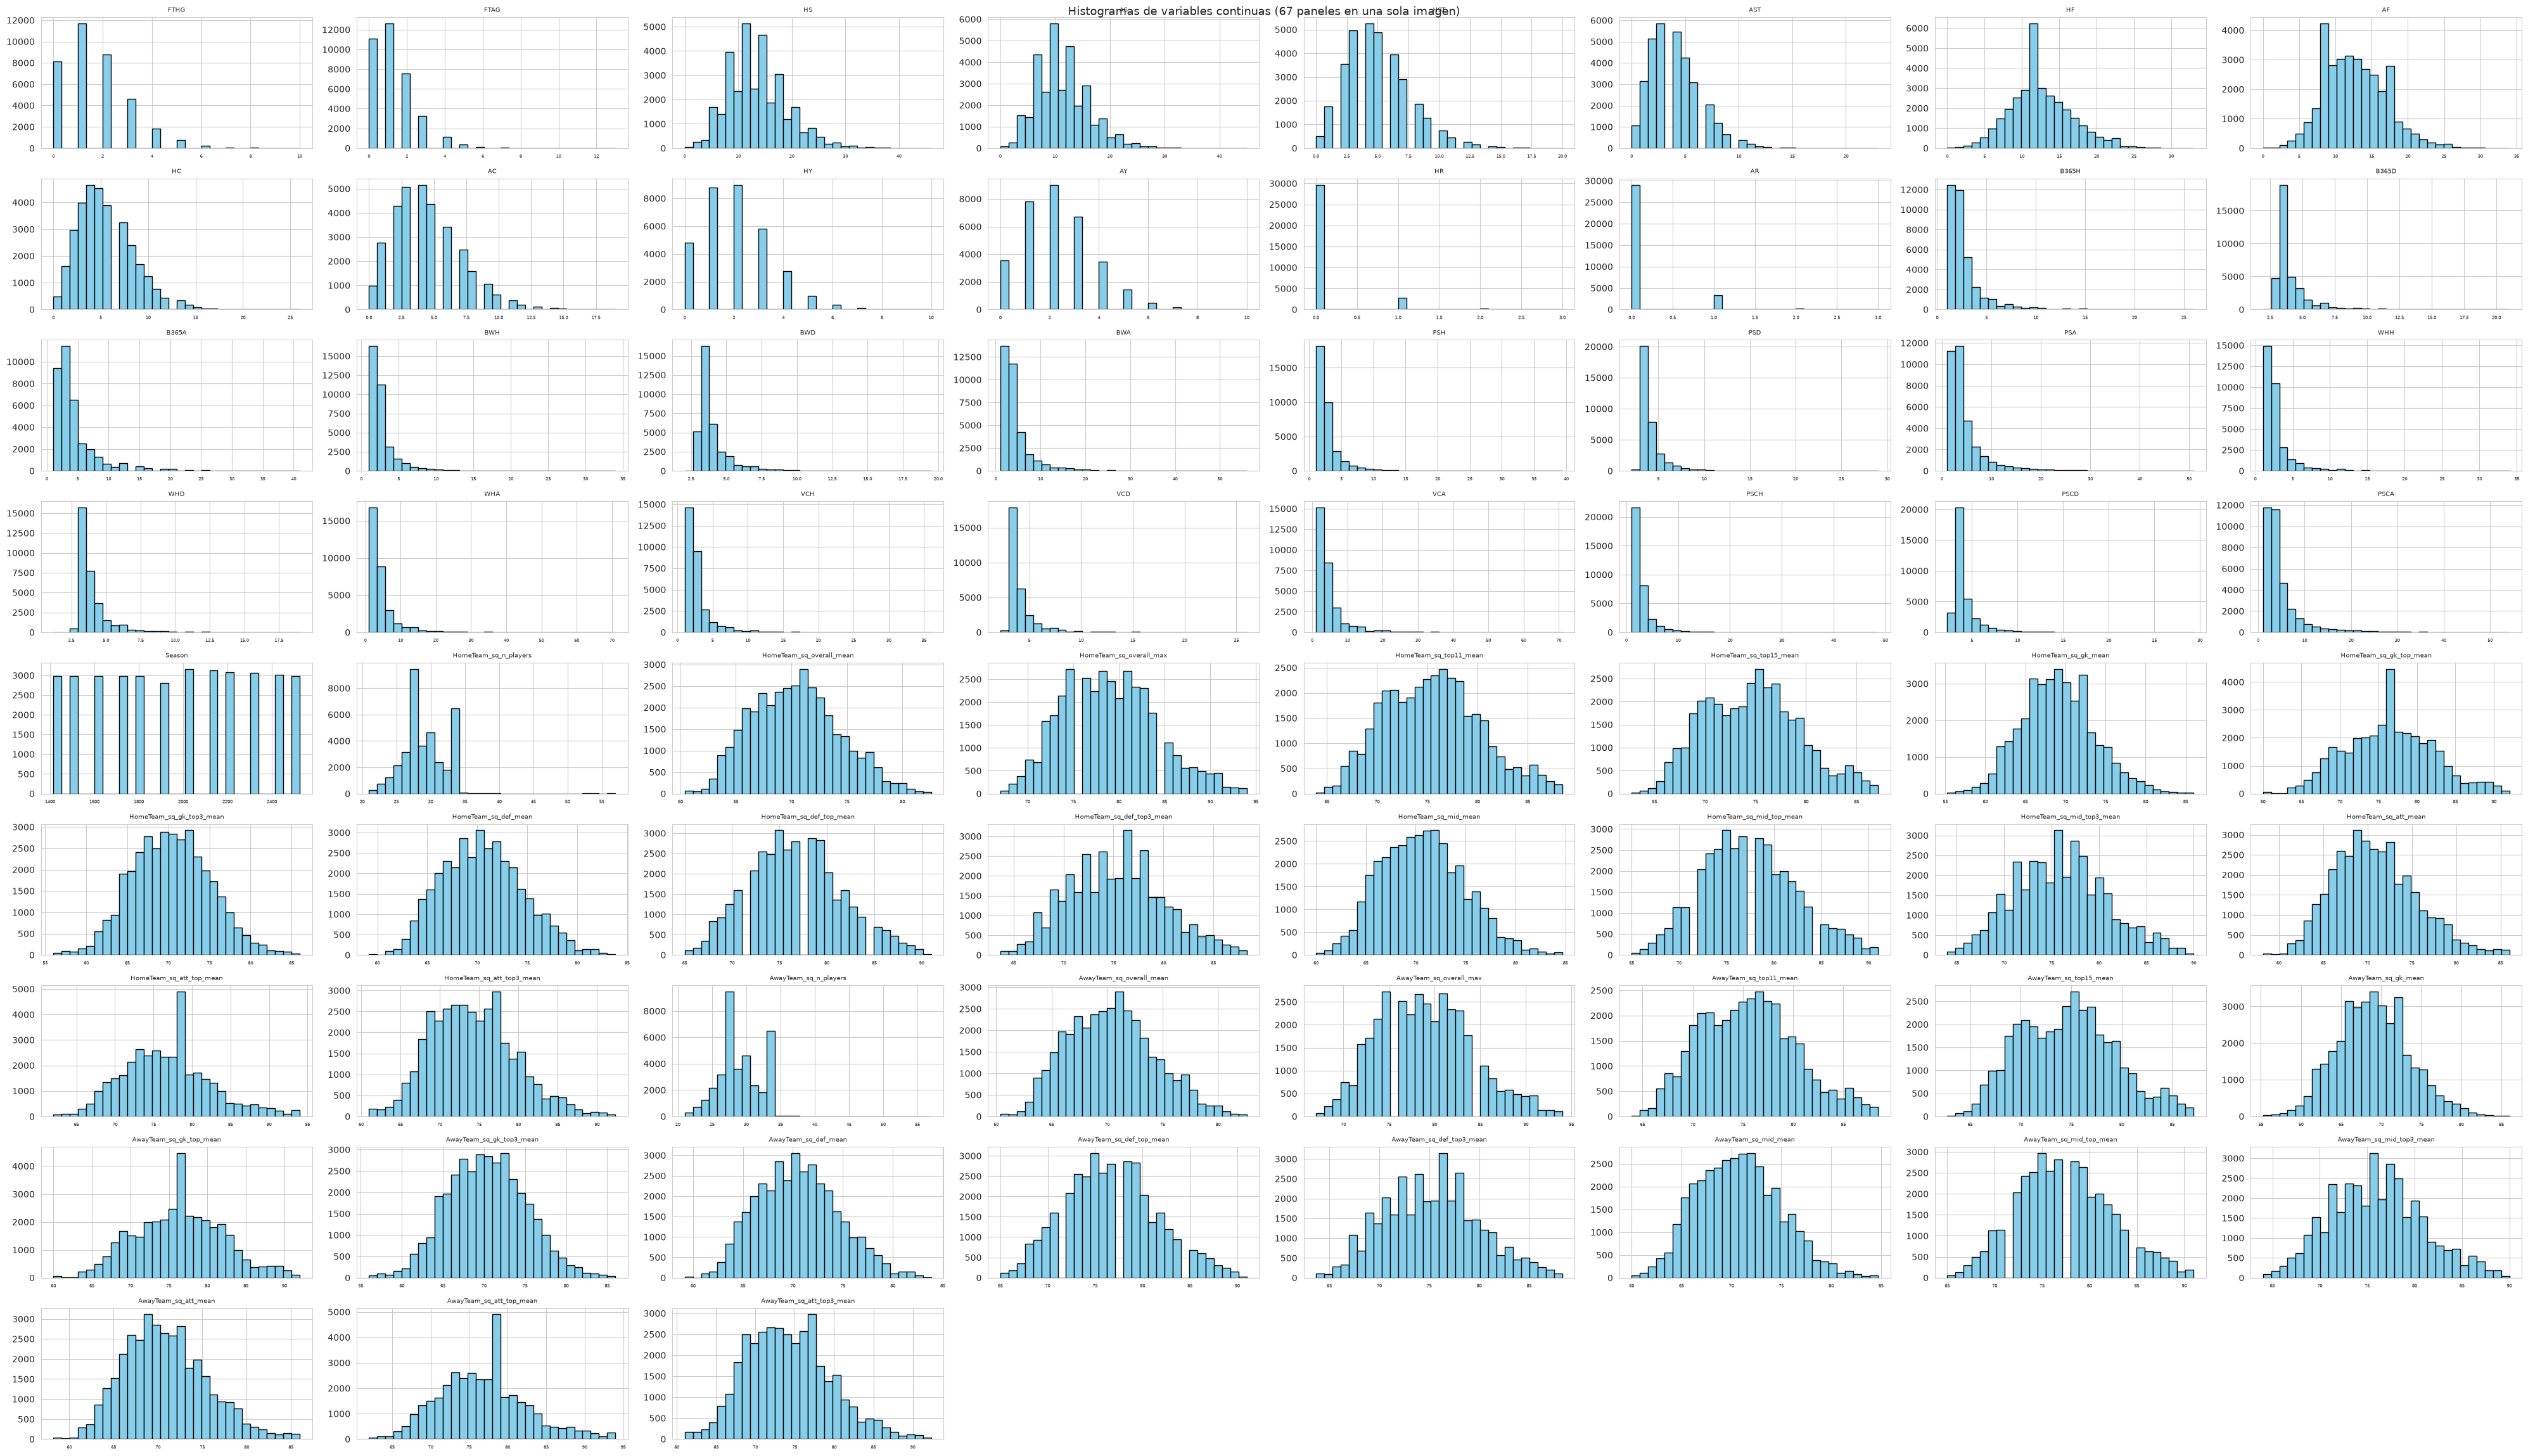

In [95]:
def graficar_hist(columnas, titulo, cols_por_fila=8, bins=30):
    n = len(columnas)
    if n == 0:
        print('Sin columnas para graficar:', titulo)
        return
    filas = int(np.ceil(n / cols_por_fila))
    fig, axes = plt.subplots(filas, cols_por_fila, figsize=(5 * cols_por_fila, 2.6 * filas))
    axes = np.atleast_2d(axes)
    for ax, c in zip(axes.ravel(), columnas):
        s = df_clean[c].dropna()
        ax.hist(s, bins=bins, color='skyblue', edgecolor='black')
        ax.set_title(c, fontsize=7)
        ax.tick_params(axis='x', labelsize=5)
    for ax in axes.ravel()[n:]:
        ax.axis('off')
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()

# Una sola imagen con TODAS las variables continuas (se hace scroll en el notebook)
bloques_cont = [continuas]
graficar_hist(continuas, f'Histogramas de variables continuas ({len(continuas)} paneles en una sola imagen)')


**Lo que se observa:**
- Goles, tiros, faltas y tarjetas tienen **sesgo positivo** (cola hacia la derecha) con máximos
  legítimos (p. ej. 13 goles del visitante).
- Las cuotas de cierre 1X2 de Pinnacle (`PSCH`/`PSCD`/`PSCA`) están sesgadas con el pico en cuotas
  bajas: la masa de partidos son favoritos claros.
- El rango intercuartil de las continuas es el esperado en fútbol; nada indica errores de medición.

Para completar el univariado, visualizamos las **variables binarias** con barras de
frecuencia, confirmando que son flags 0/1 puros (presencia/ausencia).

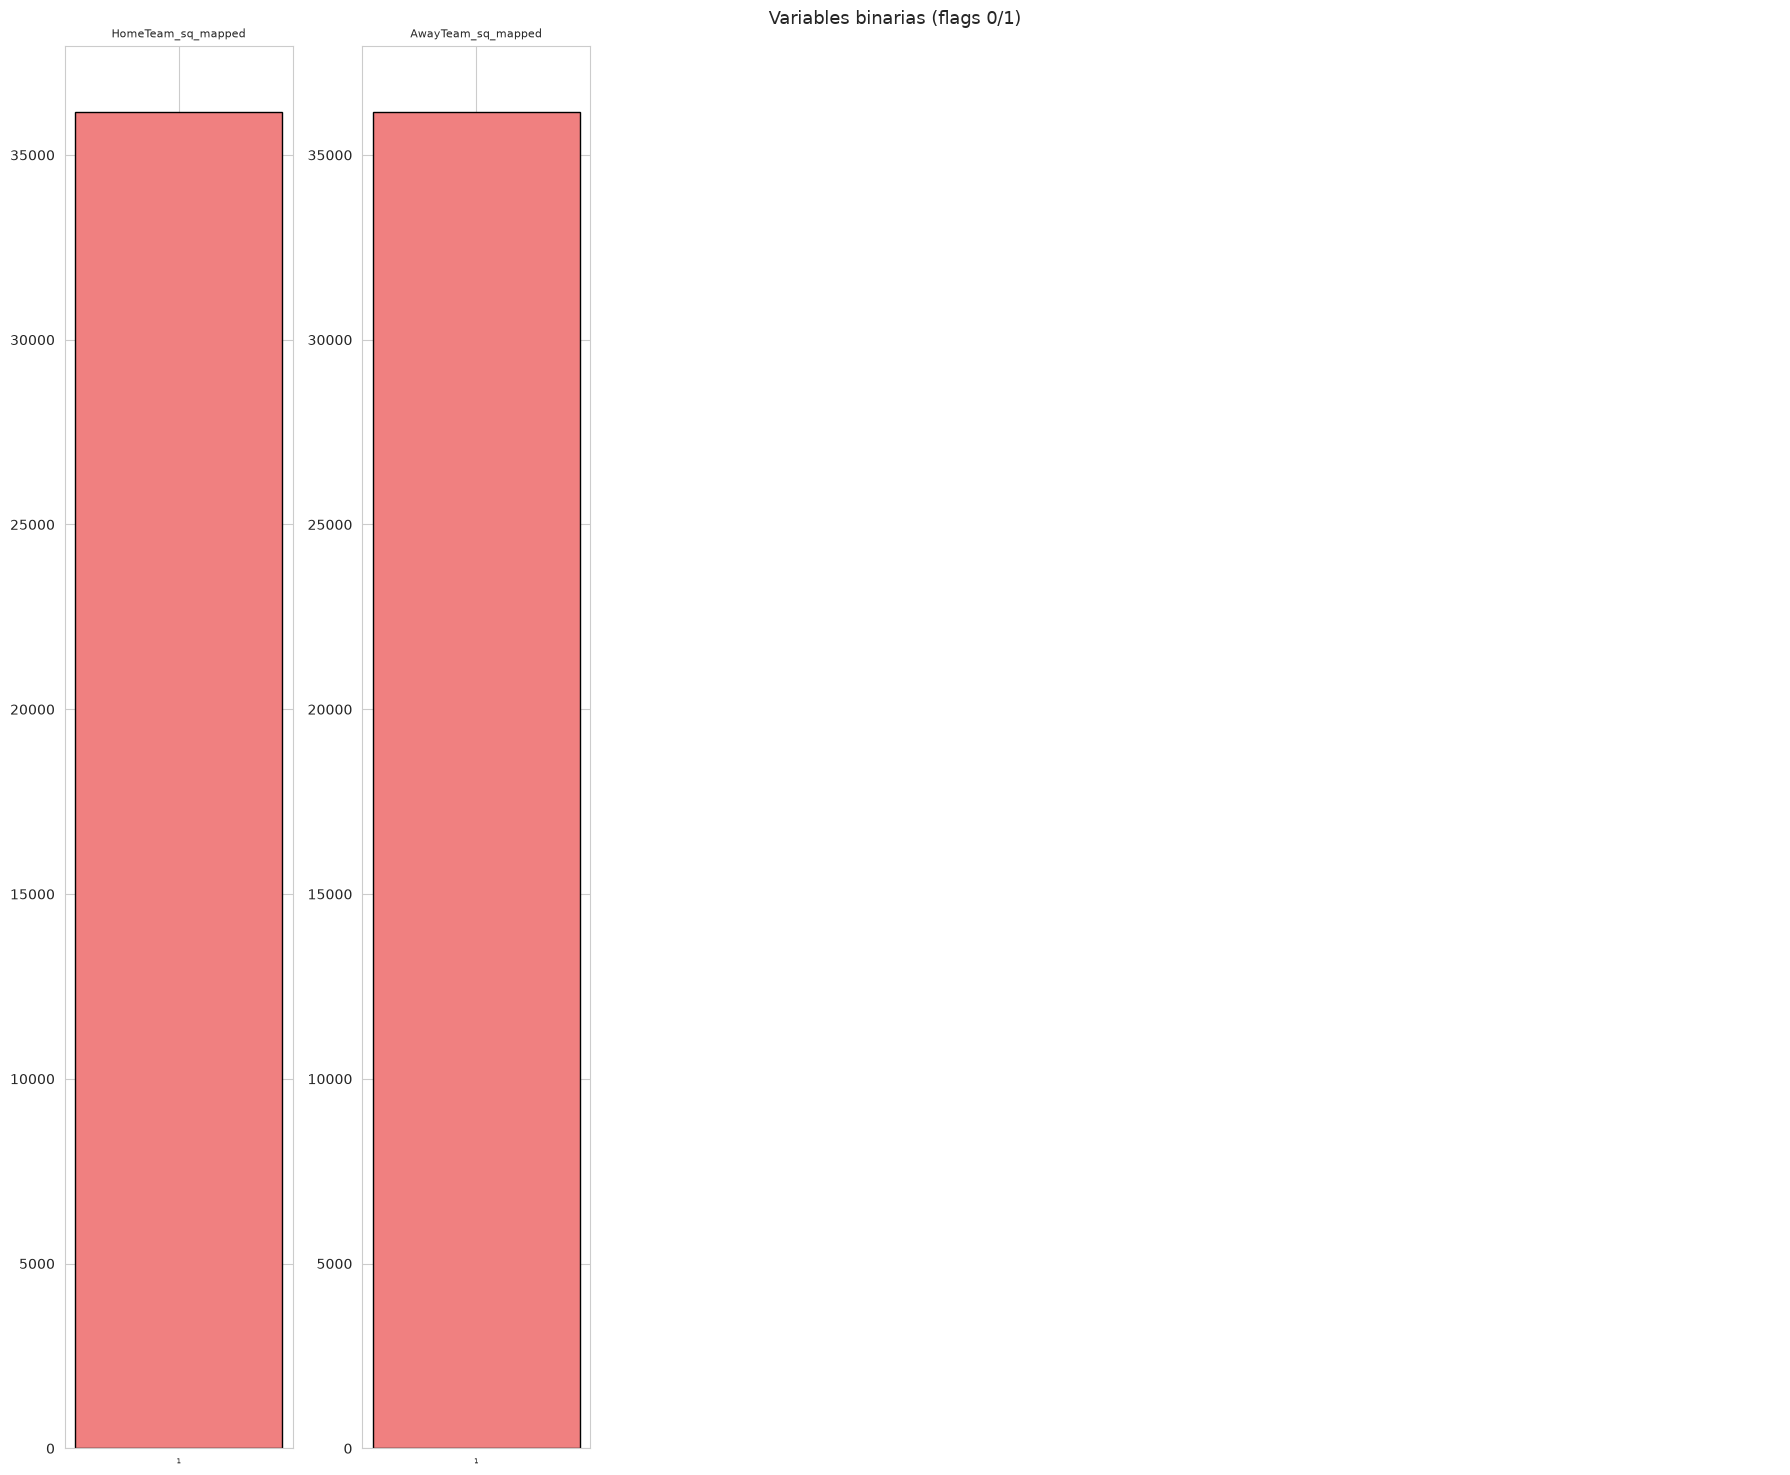

In [96]:
def graficar_binarias(columnas, cols_por_fila=6, figsize=(18, 15)):
    n = len(columnas)
    if n == 0:
        return
    filas = int(np.ceil(n / cols_por_fila))
    fig, axes = plt.subplots(filas, cols_por_fila, figsize=figsize)
    axes = np.atleast_2d(axes)
    for ax, c in zip(axes.ravel(), columnas):
        vc = df_clean[c].value_counts().sort_index()
        ax.bar(vc.index.astype(str), vc.values, color='lightcoral', edgecolor='black')
        ax.set_title(c, fontsize=8)
        ax.tick_params(axis='x', labelsize=5)
    for ax in axes.ravel()[n:]:
        ax.axis('off')
    fig.suptitle('Variables binarias (flags 0/1)', fontsize=13)
    plt.tight_layout()
    plt.show()

graficar_binarias(binarias)

**Lo que se observa:** son flags 0/1 puros: `*_sq_mapped` indica si el equipo tenía snapshot de
plantilla (hoy siempre 1, así que no aporta información) y no se usarán como variables.

Vamos a verificar si existen **filas duplicadas** (el mismo partido cargado dos veces),
que inflarían el dataset y duplicarían información durante el entrenamiento.

In [97]:
print("exact duplicate rows:", df_clean.duplicated().sum())
df_clean[df_clean.duplicated(keep=False)].sort_values(list(df_clean.columns)).head(6)

exact duplicate rows: 0


,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,B365H,B365D,B365A,BWH,BWD,BWA,PSH,PSD,PSA,WHH,WHD,WHA,VCH,VCD,VCA,PSCH,PSCD,PSCA,Season,HomeTeam_sq_n_players,HomeTeam_sq_overall_mean,HomeTeam_sq_overall_max,HomeTeam_sq_top11_mean,HomeTeam_sq_top15_mean,HomeTeam_sq_gk_mean,HomeTeam_sq_gk_top_mean,HomeTeam_sq_gk_top3_mean,HomeTeam_sq_def_mean,HomeTeam_sq_def_top_mean,HomeTeam_sq_def_top3_mean,HomeTeam_sq_mid_mean,HomeTeam_sq_mid_top_mean,HomeTeam_sq_mid_top3_mean,HomeTeam_sq_att_mean,HomeTeam_sq_att_top_mean,HomeTeam_sq_att_top3_mean,HomeTeam_sq_mapped,AwayTeam_sq_n_players,AwayTeam_sq_overall_mean,AwayTeam_sq_overall_max,AwayTeam_sq_top11_mean,AwayTeam_sq_top15_mean,AwayTeam_sq_gk_mean,AwayTeam_sq_gk_top_mean,AwayTeam_sq_gk_top3_mean,AwayTeam_sq_def_mean,AwayTeam_sq_def_top_mean,AwayTeam_sq_def_top3_mean,AwayTeam_sq_mid_mean,AwayTeam_sq_mid_top_mean,AwayTeam_sq_mid_top3_mean,AwayTeam_sq_att_mean,AwayTeam_sq_att_top_mean,AwayTeam_sq_att_top3_mean,AwayTeam_sq_mapped


**Lo que se observa:** no hay duplicados exactos. La clave compuesta
`(Div, Season, Date, HomeTeam, AwayTeam)` identifica cada partido de forma única, así que no es
necesario deduplicar.

## Outliers: detectar y luego decidir

Usamos la **regla del IQR**: un valor es outlier si queda fuera de $[Q_1 - 1.5\cdot\text{IQR},\; Q_3 + 1.5\cdot\text{IQR}]$. Sabemos que **no todo extremo es un error**, así que primero detectamos con boxplots e histogramas (con las vallas IQR dibujadas) y recién después decidimos qué hacer con ellos.

Vamos a graficar los **boxplots de todas las variables continuas** (en bloques). Cada
punto fuera del boxplot es un outlier por la regla del IQR; en el título mostramos cuántos valores fueron flaggeados.

/tmp/ipykernel_60578/184735253.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, showfliers=True)
/tmp/ipykernel_60578/184735253.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, showfliers=True)
/tmp/ipykernel_60578/184735253.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, showfliers=True)
/tmp/ipykernel_60578/184735253.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, showfliers=True)
/tmp/ipykernel_60578/184735253.py:17: Ma

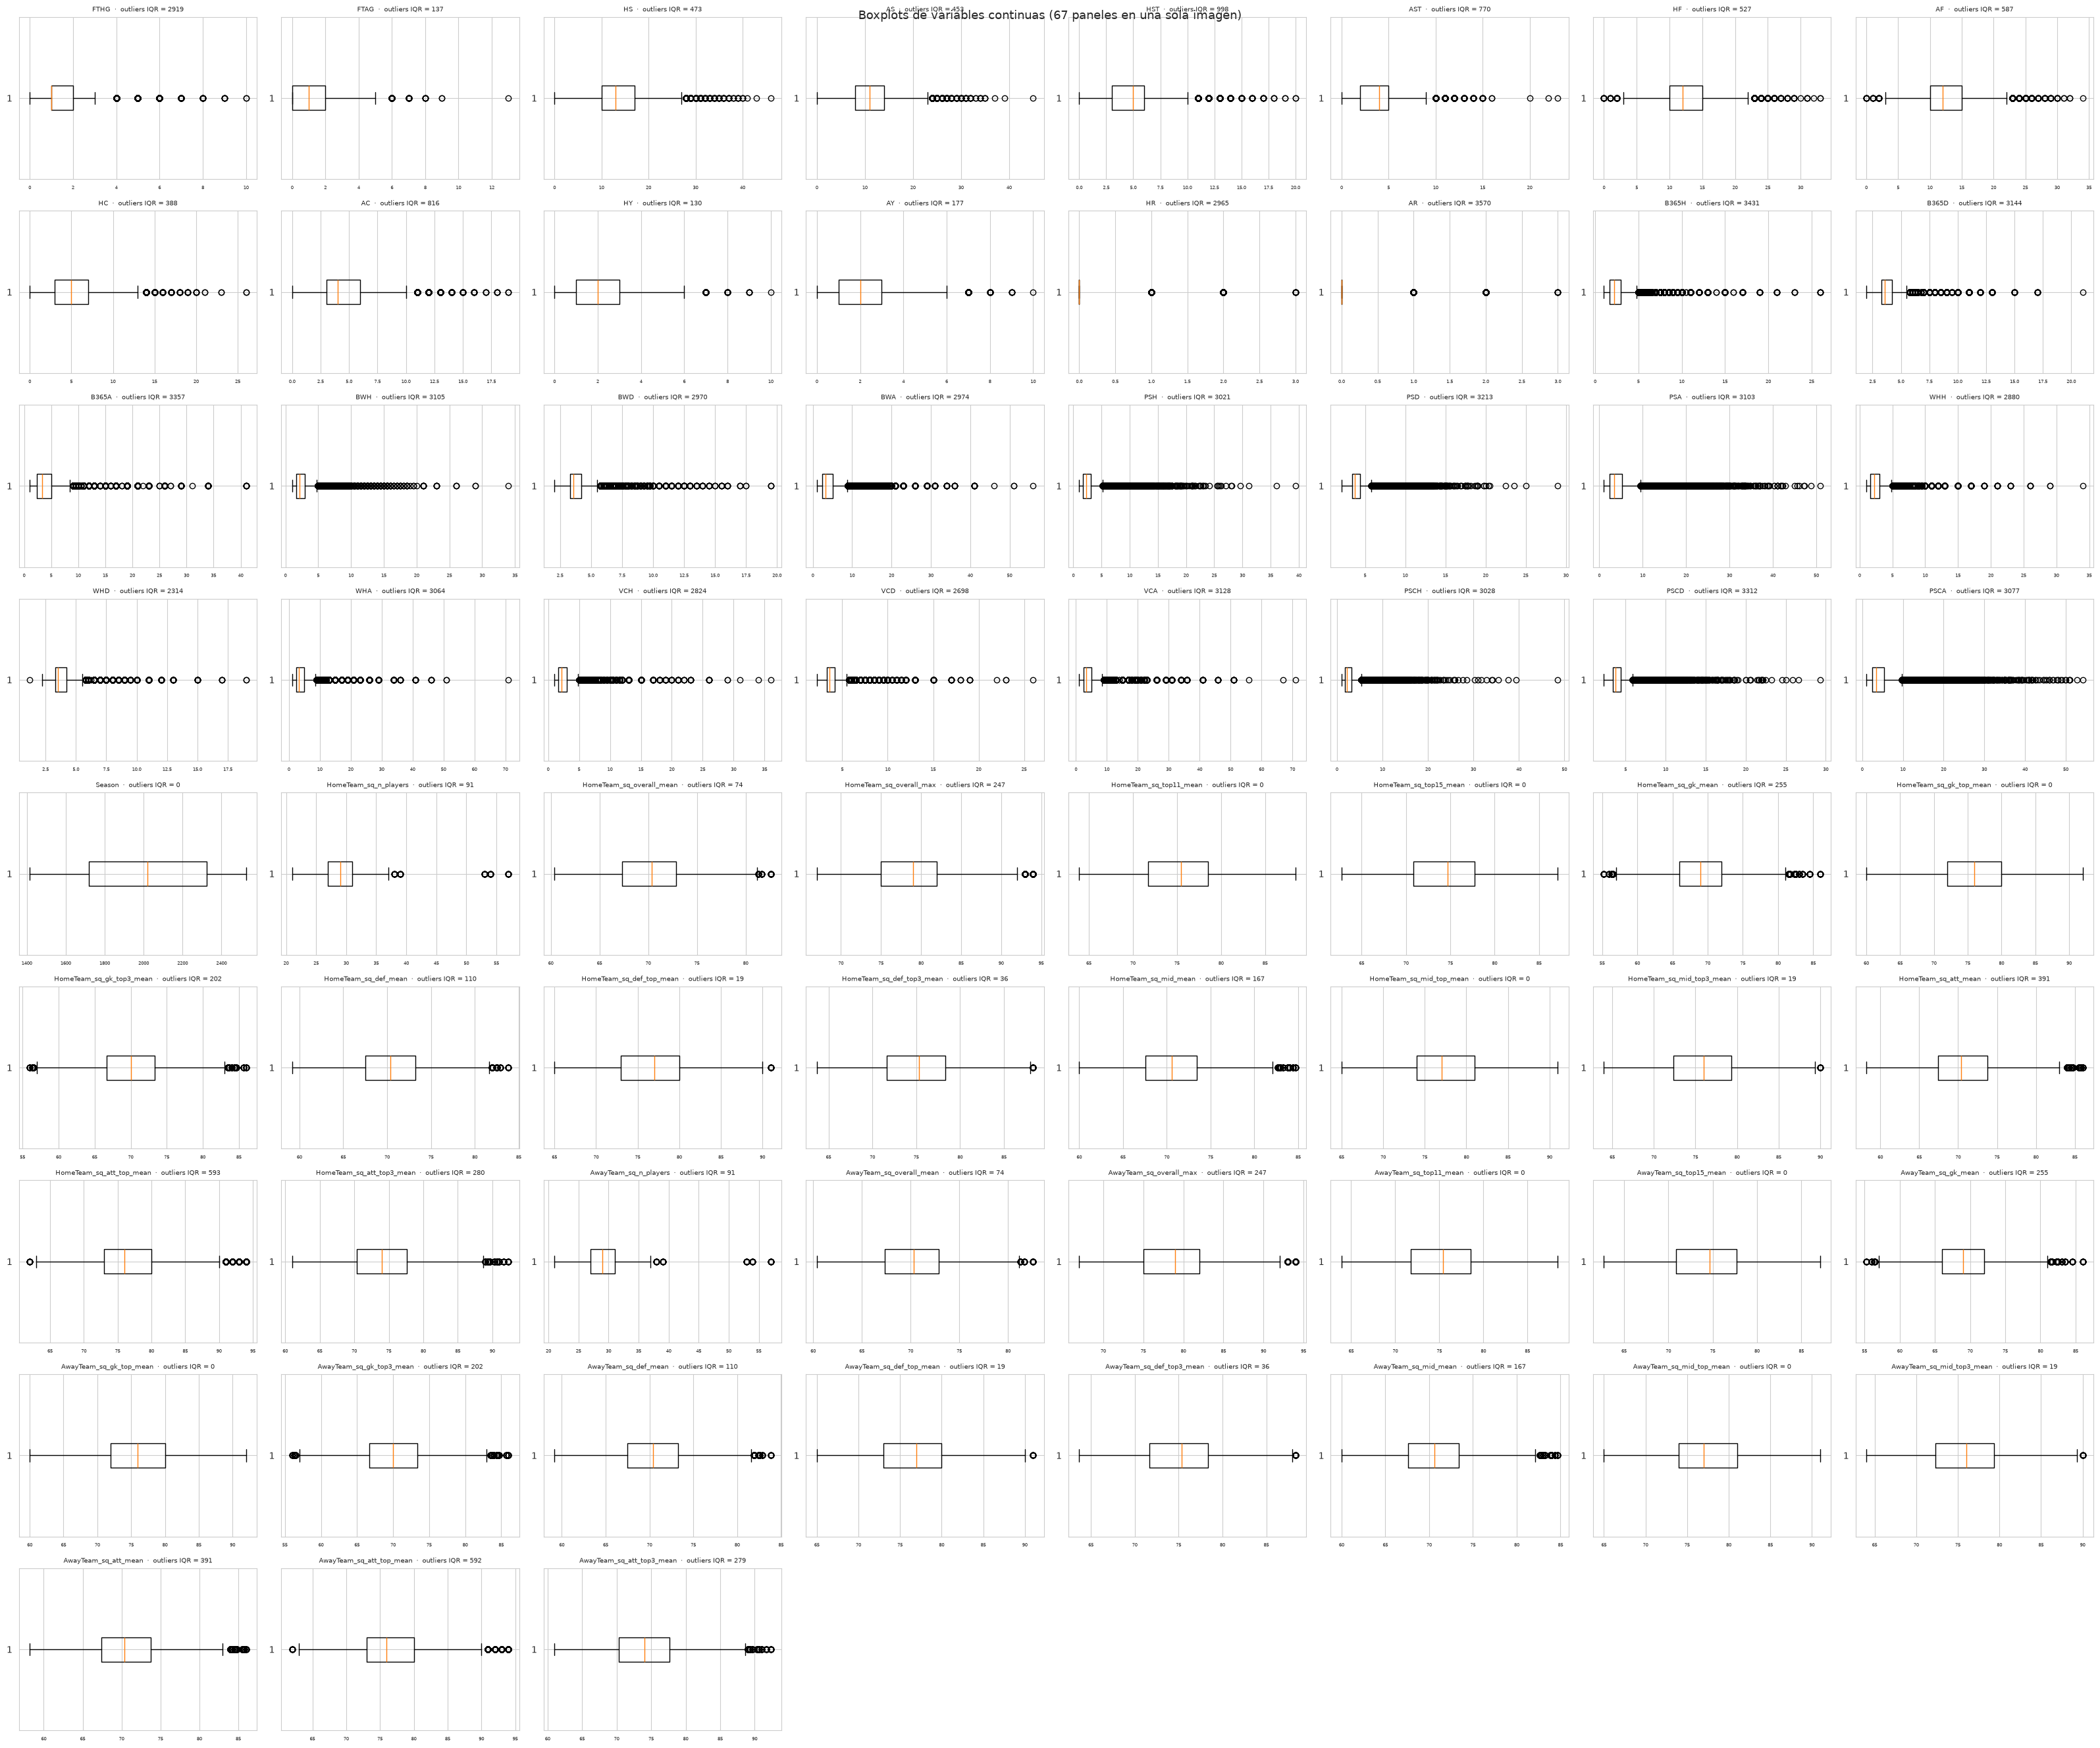

In [98]:
def iqr_fences(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

def graficar_boxplots(columnas, titulo, cols_por_fila=8):
    n = len(columnas)
    if n == 0:
        return
    filas = int(np.ceil(n / cols_por_fila))
    fig, axes = plt.subplots(filas, cols_por_fila, figsize=(4 * cols_por_fila, 3* filas))
    axes = np.atleast_2d(axes)
    for ax, c in zip(axes.ravel(), columnas):
        s = df_clean[c].dropna()
        lo, hi = iqr_fences(s)
        nout = int(((s < lo) | (s > hi)).sum())
        ax.boxplot(s, vert=False, showfliers=True)
        ax.set_title(f"{c}  ·  outliers IQR = {nout}", fontsize=7)
        ax.tick_params(axis='x', labelsize=5)
    for ax in axes.ravel()[n:]:
        ax.axis('off')
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()

graficar_boxplots(continuas, f'Boxplots de variables continuas ({len(continuas)} paneles en una sola imagen)')


**Lo que se observa:** en las variables de goles, tiros, faltas y tarjetas los puntos
extremos son pocos (<2%) y corresponden a partidos reales atípicos. En las cuotas los "outliers"
son partidos muy desequilibrados (favoritos claros), no errores de medición.

Ahora los **histogramas de las mismas variables con las vallas IQR dibujadas** (líneas
rojas discontinuas) y el rango `[lo, hi]` en el título: ubican visualmente dónde empiezan los
outliers en cada variable.

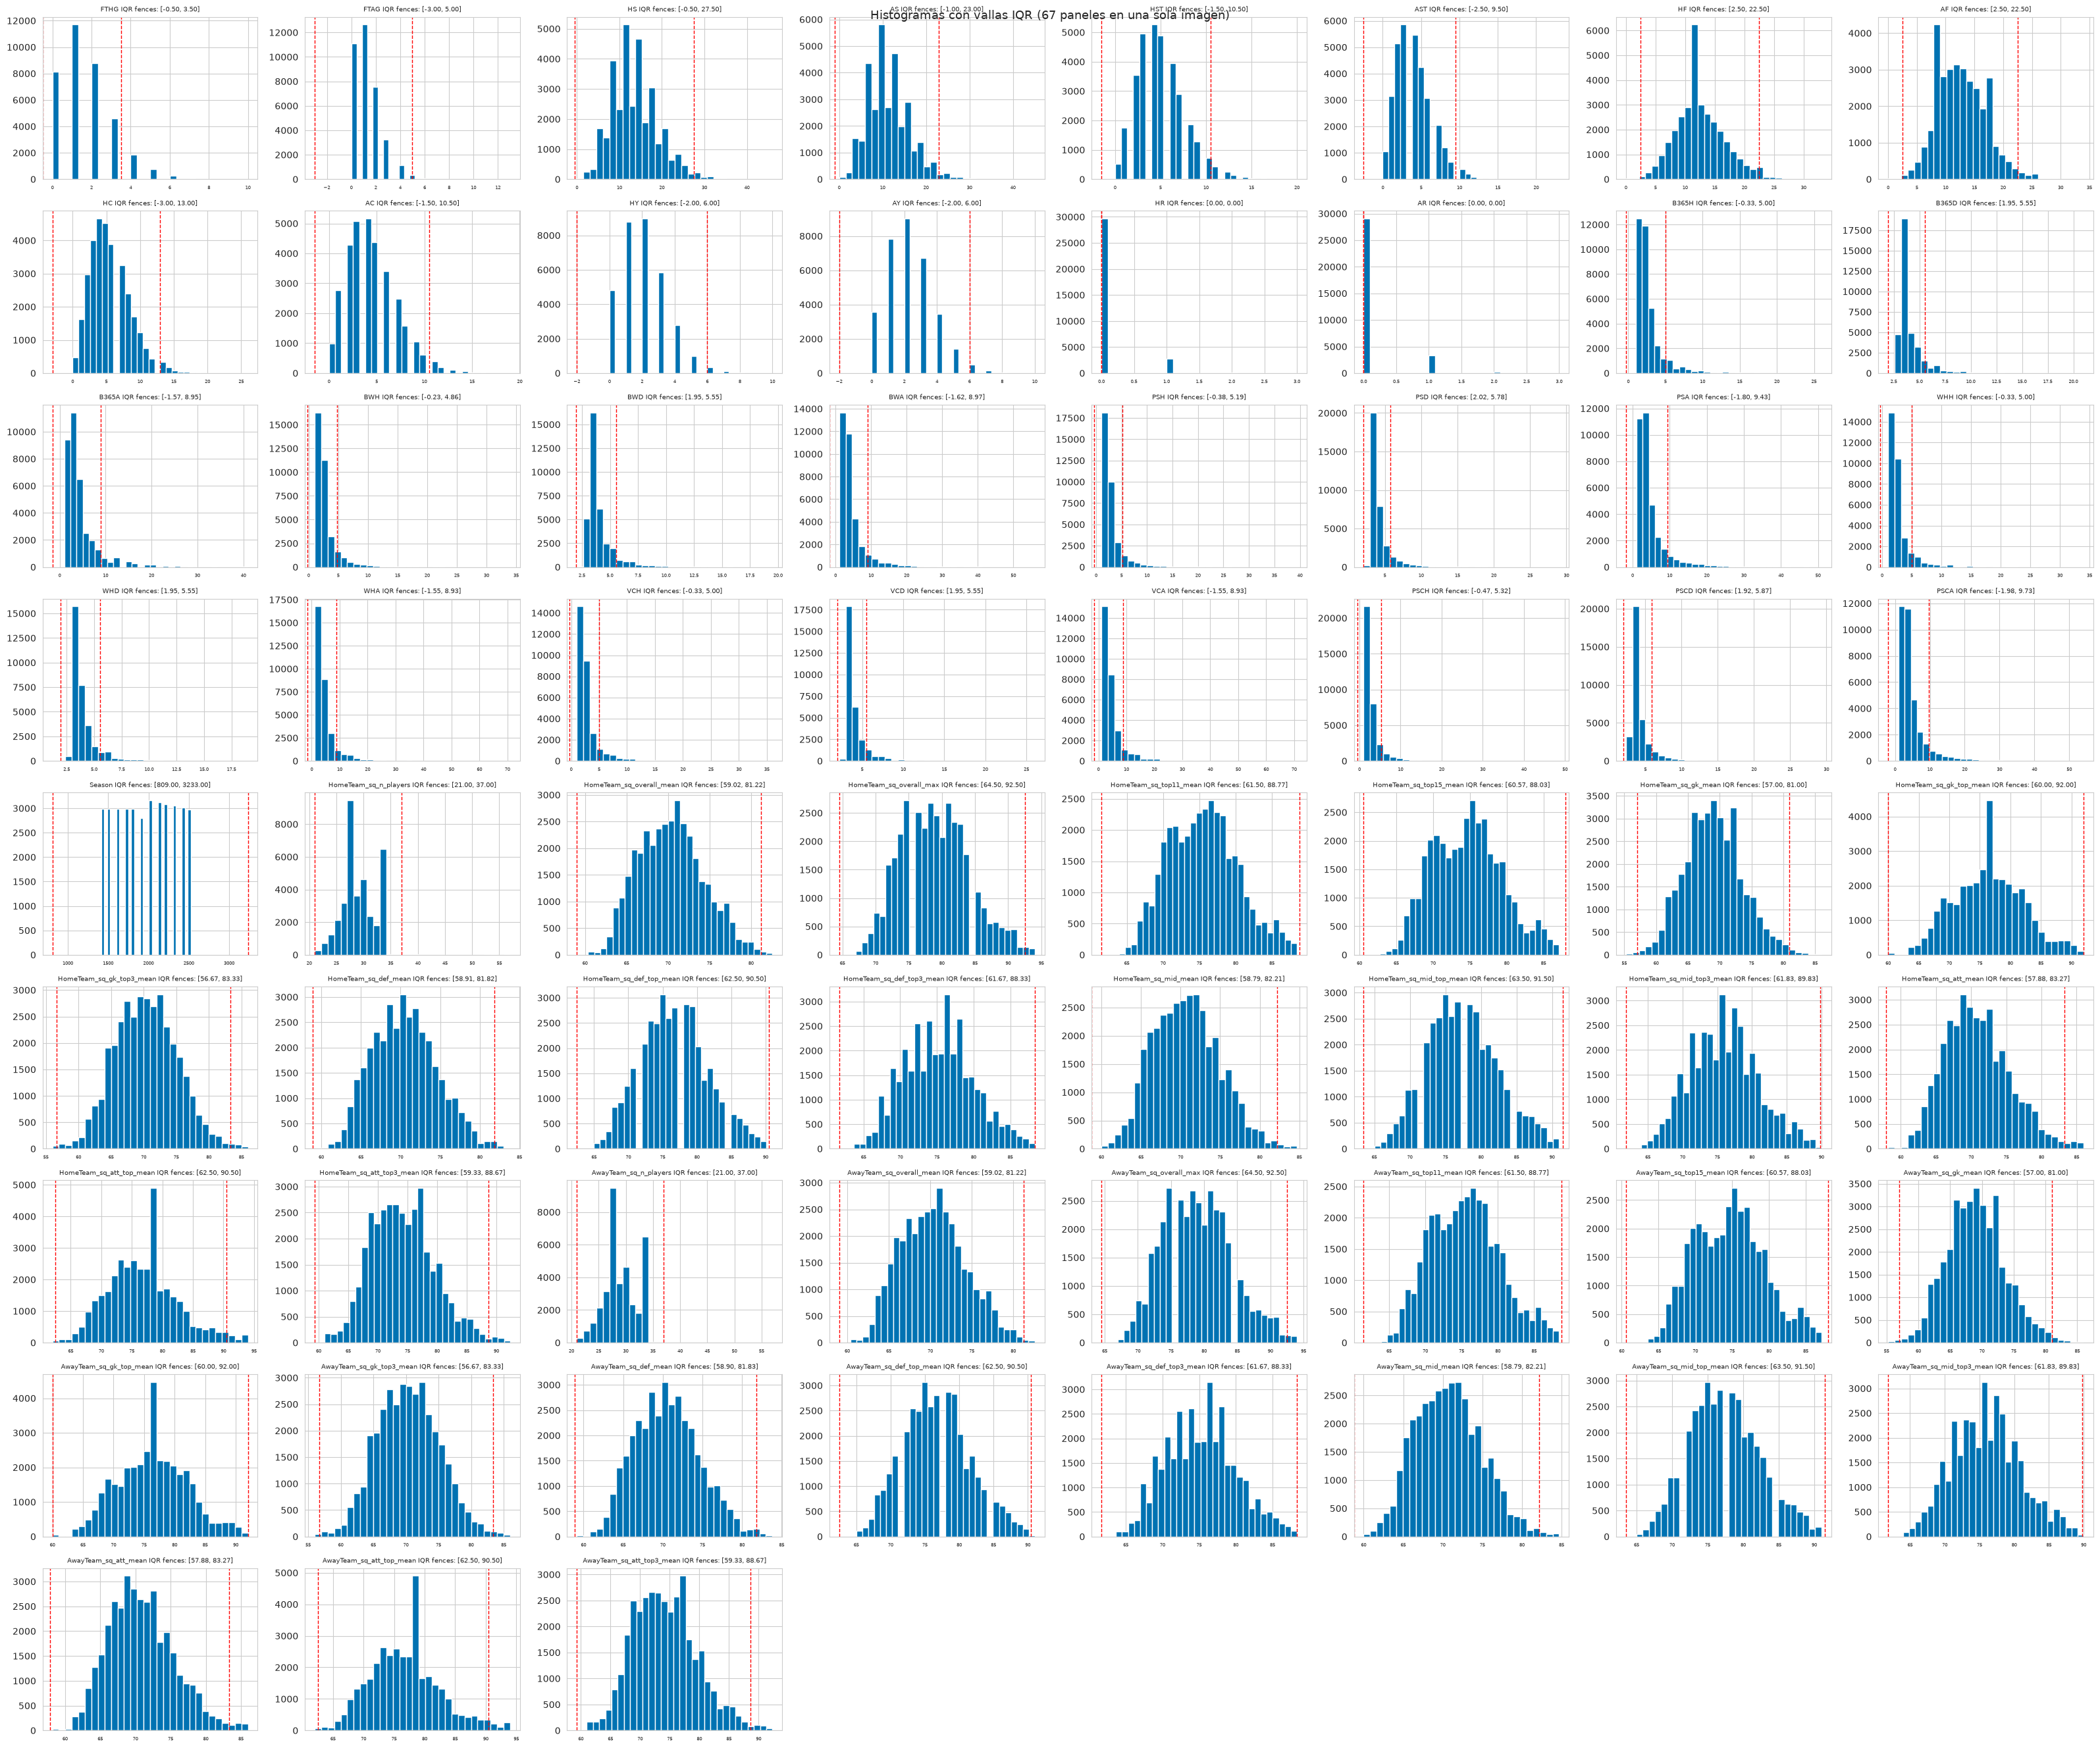

In [99]:
def graficar_hist_iqr(columnas, titulo, cols_por_fila=8, bins=30):
    n = len(columnas)
    if n == 0:
        return
    filas = int(np.ceil(n / cols_por_fila))
    fig, axes = plt.subplots(filas, cols_por_fila, figsize=(4 * cols_por_fila, 3 * filas))
    axes = np.atleast_2d(axes)
    for ax, c in zip(axes.ravel(), columnas):
        s = df_clean[c].dropna()
        lo, hi = iqr_fences(s)
        ax.hist(s, bins=bins, color='#0072B2', edgecolor='white')
        ax.axvline(lo, color='red', ls='--', lw=1)
        ax.axvline(hi, color='red', ls='--', lw=1)
        ax.set_title(f"{c} IQR fences: [{lo:.2f}, {hi:.2f}]", fontsize=7)
        ax.tick_params(axis='x', labelsize=5)
    for ax in axes.ravel()[n:]:
        ax.axis('off')
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()

graficar_hist_iqr(continuas, f'Histogramas con vallas IQR ({len(continuas)} paneles en una sola imagen)')


**Lo que se observa:** confirmamos la ubicación de las colas: para goles/tiros el
extremo superior queda muy por encima de `hi` (pocos partidos rarísimos) y para las cuotas la cola
alta refleja los long-shots del mercado. Ningún valor parece un error de captura.

Como las figuras anteriores son muy extensas, hacemos un **gráfico resumen con las
variables más representativas** del proyecto: goles (`FTHG`, `FTAG`), tiros (`HS`, `AS`), cuota
media de mercado (`AvgH`, `AvgD`, `AvgA`) y squad quality (`*_sq_top11_mean`), combinando boxplot
e histograma con vallas IQR por variable.

La media de mercado (`Avg`) es la representación del mercado 1X2 que conserva el pipeline de
features: es prácticamente equivalente a las cuotas de cierre de Pinnacle (el acierto del favorito es ~54% en ambas). Las `Avg` solo existen desde 2019/20: no superan el filtro de faltantes de `df_clean` (41.4% de nulos, estructural por temporada), por eso en las figuras se leen desde el dataset crudo `df` y el modelado usa el consenso `MKT_*` de B365/BW/PS/WH en su lugar.

/tmp/ipykernel_60578/199077421.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, showfliers=True)
/tmp/ipykernel_60578/199077421.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, showfliers=True)
/tmp/ipykernel_60578/199077421.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, showfliers=True)
/tmp/ipykernel_60578/199077421.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, showfliers=True)
/tmp/ipykernel_60578/199077421.py:14: Ma

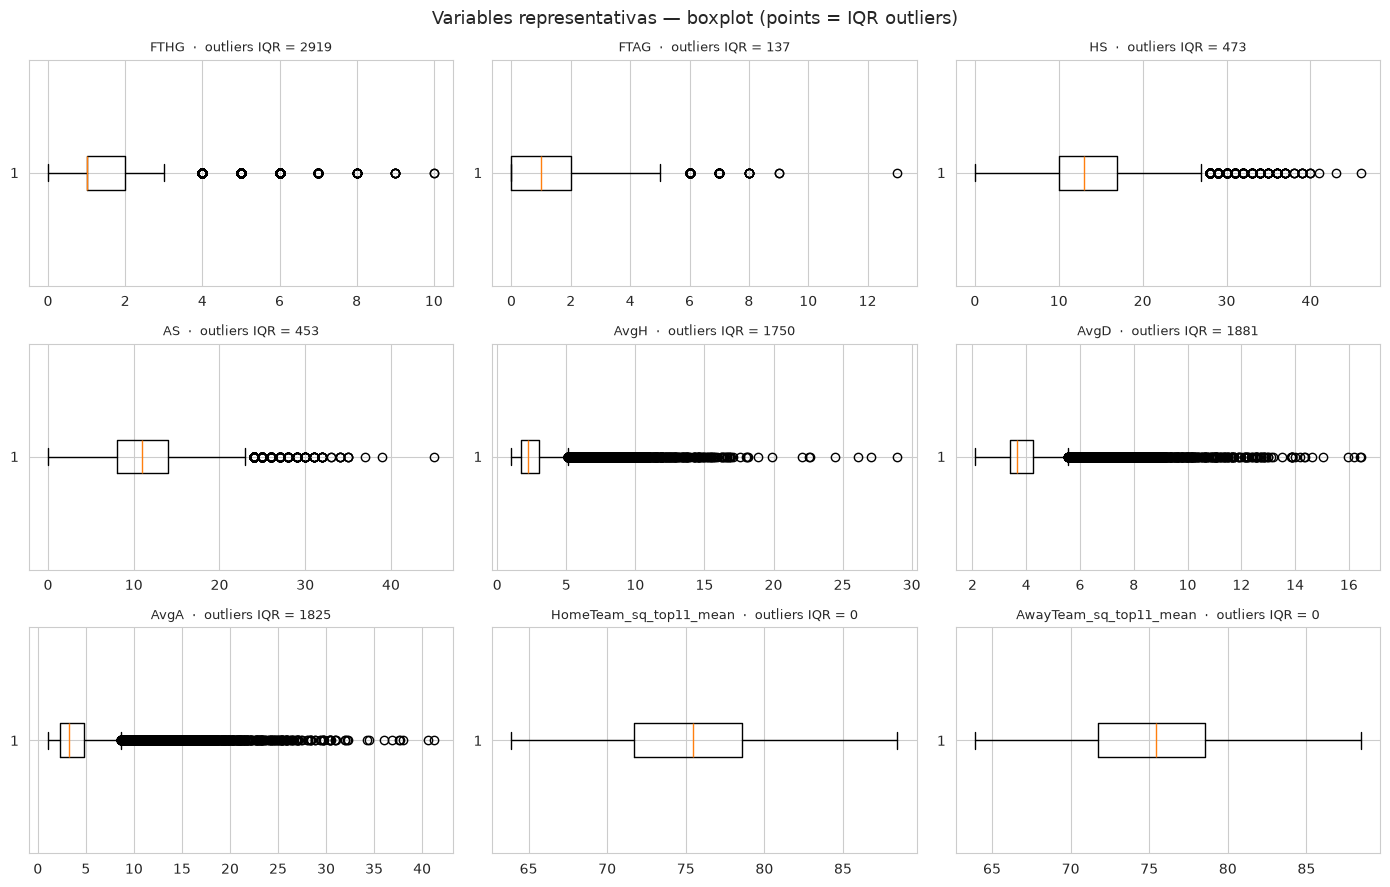

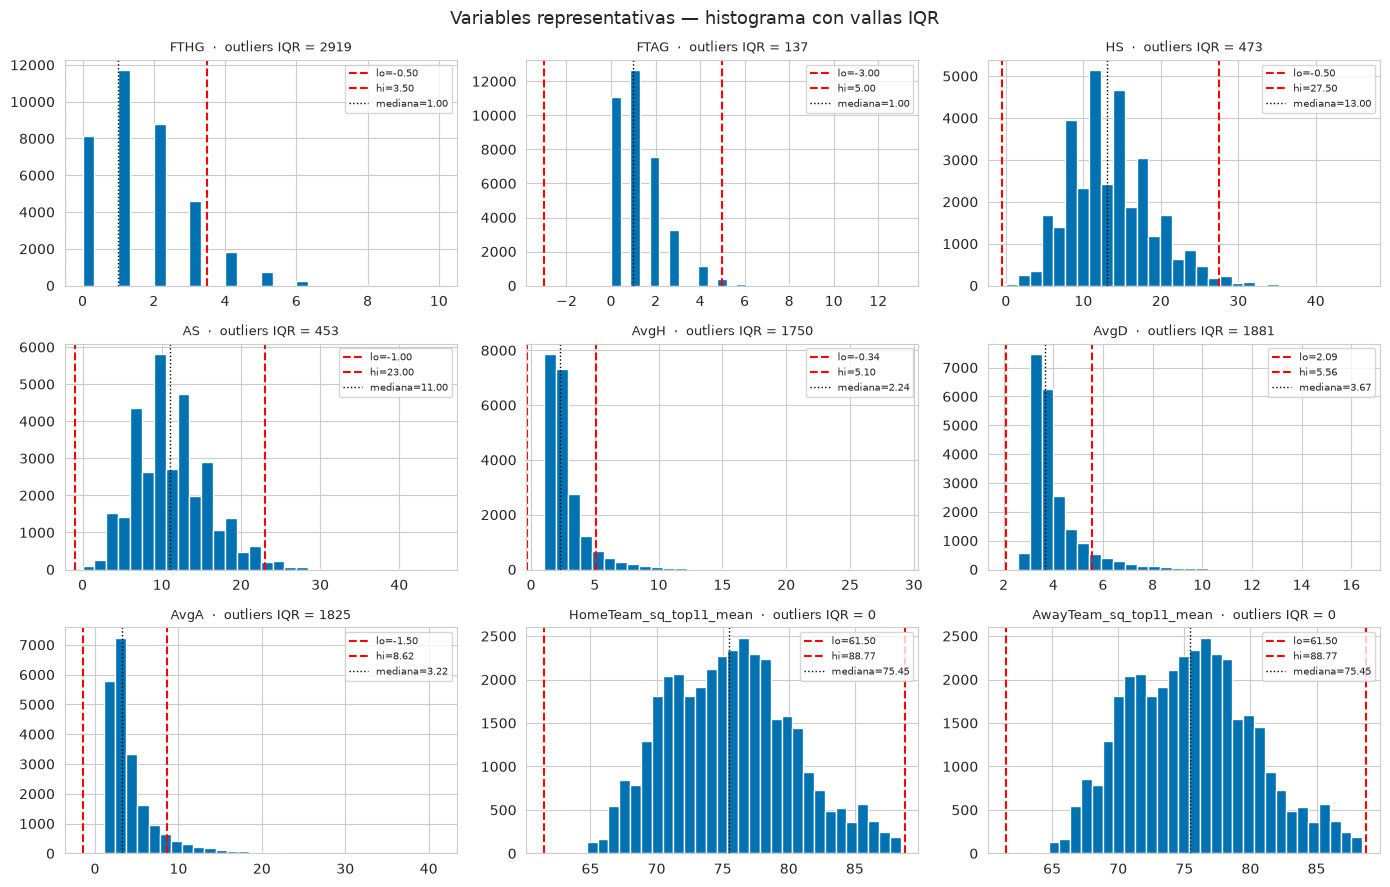

In [100]:
df_eda = df_clean.join(df[['AvgH', 'AvgD', 'AvgA']])

REPRESENTATIVAS = ['FTHG', 'FTAG', 'HS', 'AS', 'AvgH', 'AvgD', 'AvgA',
                   'HomeTeam_sq_top11_mean', 'AwayTeam_sq_top11_mean']
REPRESENTATIVAS = [c for c in REPRESENTATIVAS if c in df_eda.columns]

# Boxplot
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
axes = np.atleast_2d(axes)
for ax, c in zip(axes.ravel(), REPRESENTATIVAS):
    s = df_eda[c].dropna()
    lo, hi = iqr_fences(s)
    nout = int(((s < lo) | (s > hi)).sum())
    ax.boxplot(s, vert=False, showfliers=True)
    ax.set_title(f"{c}  ·  outliers IQR = {nout}", fontsize=9)
for ax in axes.ravel()[len(REPRESENTATIVAS):]:
    ax.axis('off')
fig.suptitle('Variables representativas — boxplot (points = IQR outliers)', fontsize=13)
plt.tight_layout()
plt.show()

# Histograma + vallas IQR
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
axes = np.atleast_2d(axes)
for ax, cx in zip(axes.ravel(), REPRESENTATIVAS):
    s = df_eda[cx].dropna()
    lo, hi = iqr_fences(s)
    nout = int(((s < lo) | (s > hi)).sum())
    ax.hist(s, bins=30, color='#0072B2', edgecolor='white')
    ax.axvline(lo, color='red', ls='--', lw=1.5, label=f'lo={lo:.2f}')
    ax.axvline(hi, color='red', ls='--', lw=1.5, label=f'hi={hi:.2f}')
    ax.axvline(s.median(), color='k', ls=':', lw=1, label=f'mediana={s.median():.2f}')
    ax.set_title(f"{cx}  ·  outliers IQR = {nout}", fontsize=9)
    ax.legend(fontsize=7)
for ax in axes.ravel()[len(REPRESENTATIVAS):]:
    ax.axis('off')
fig.suptitle('Variables representativas — histograma con vallas IQR', fontsize=13)
plt.tight_layout()
plt.show()

**Lo que se observa:** los outliers en goles y tiros son extremos reales de partidos atípicos; en las cuotas (`AvgH`/`AvgD`/`AvgA`) son partidos muy desequilibrados (long-shots), justo donde se concentra el ROI en un backtest de *value bets*. Por
eso **no se eliminan ni se capan**.

Acá no las vamos a eliminar por estas razones:
1. **En cuotas son puros**: `AvgA` puede llegar a 41.2 (o `AvgH` a 29.0) porque es un “seguro” para la casa de apuestas, es decir equipo grande vs equipo chico. Es información real del mercado, no un error.
2. **En estadísticas son extremos reales**: 30+ tiros o 5+ goles son partidos atípicos pero reales.
3. **Un modelo calibrado los necesita**: este proyecto busca probabilidades y value bets; la cola de cuotas largas (long-shots) es justo donde se gana o se pierde el ROI. Eliminarlos o caparlos sesga las probabilidades predichas.

## Análisis Bivariado

Ahora estudiamos **pares de variables**: cómo las cuotas y la calidad de plantilla se relacionan con
el resultado real `FTR`. Esto revela la señal que aprovechará el modelo y motiva las decisiones de
ingeniería de features: qué variables son informativas, cuáles son redundantes y en qué orden de
importancia.

Vamos a ver si la **cuota media de mercado** (`AvgH`, `AvgD`, `AvgA`) distingue el
resultado real. Si el mercado es informativo, la cuota correspondiente al resultado ocurrido debería
ser menor (se estimó más probable). Agrupamos la cuota media por clase de `FTR` y dibujamos boxplots.

La media de mercado es el promedio 1X2 de las principales casas. Es virtualmente idéntica a las
cuotas de cierre de Pinnacle (`PSCH`/`PSCD`/`PSCA`): el acierto del favorito es ~54% en ambas y la información mutua con `FTR` es casi la misma. Por cobertura, el modelo usa el consenso de probabilidades implícitas `MKT_*` (apertura) en vez de `Avg`.

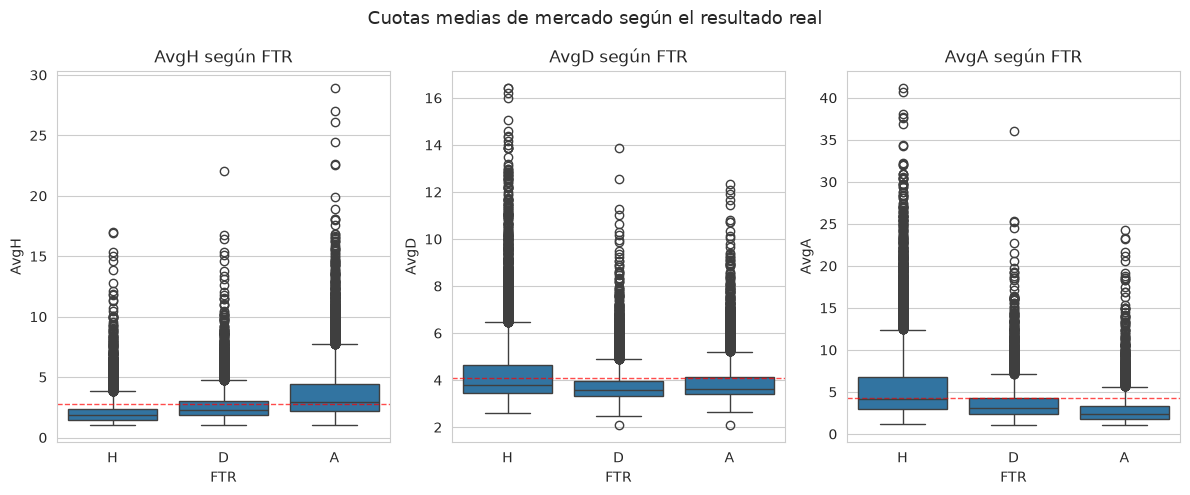

,AvgH,AvgD,AvgA
FTR,,,
A,3.707,3.917,2.878
D,2.678,3.809,3.763
H,2.121,4.333,5.624


In [101]:
df_eda = df_clean.join(df[['AvgH', 'AvgD', 'AvgA']])

fig, axes = plt.subplots(1, 3, figsize=(12, 5))
for ax, cx in zip(axes, ['AvgH', 'AvgD', 'AvgA']):
    sns.boxplot(data=df_eda, x='FTR', y=cx, order=['H', 'D', 'A'], ax=ax)
    ax.axhline(df_eda[cx].mean(), color='red', ls='--', lw=1, alpha=0.7)
    ax.set_title(f'{cx} según FTR')
plt.suptitle('Cuotas medias de mercado según el resultado real', fontsize=13)
plt.tight_layout()
plt.show()

df_eda.groupby('FTR')[['AvgH', 'AvgD', 'AvgA']].mean().round(3)

**Lo que se observa:** cuando gana el local, `AvgH` es sustancialmente menor que cuando pierde, y `AvgA` cae cuando gana el visitante. Las cuotas medias de mercado anticipan el resultado con buena precisión: son la señal pre-partido más fuerte y el *baseline* del mercado. Son prácticamente equivalentes a las cuotas de cierre de Pinnacle, de modo que `Avg` es una representación compacta y suficiente del mercado.

Ahora la relación entre **squad quality** y resultado: creamos la diferencia de rating
del once ideal `local − visitante` (`HomeTeam_sq_top11_mean − AwayTeam_sq_top11_mean`). Si la
plantilla importa, la diferencia debería ser positiva cuando gana el local y negativa cuando gana el
visitante.

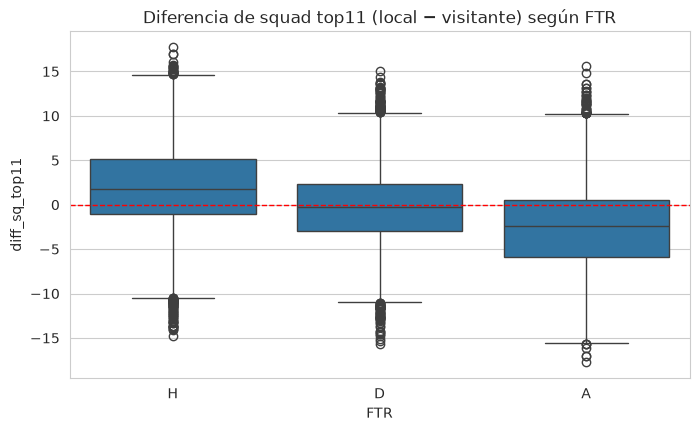

FTR
A   -2.58
D   -0.33
H    1.97
Name: diff_sq_top11, dtype: float64

In [102]:
df_clean['diff_sq_top11'] = df_clean['HomeTeam_sq_top11_mean'] - df_clean['AwayTeam_sq_top11_mean']

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df_clean, x='FTR', y='diff_sq_top11', order=['H', 'D', 'A'])
plt.axhline(0, color='red', ls='--', lw=1)
plt.title('Diferencia de squad top11 (local − visitante) según FTR')
plt.show()

df_clean.groupby('FTR')['diff_sq_top11'].mean().round(2)

**Lo que se observa:** cuando gana el local la diferencia media es positiva, cuando gana el visitante es negativa y el empate queda en el medio. La plantilla aporta señal complementaria a las cuotas, útil sobre todo a inicios de temporada cuando aún no hay historial de forma.

Finalmente, la **matriz de correlación de todas las variables numéricas de `df_clean`**: goles, tiros, cuotas medias, squad quality y banderas, para identificar relaciones lineales y **multicolinealidad** (variables que repiten información). Como son muchas columnas, primero el mapa completo en color y luego un detalle anotado de las variables clave (goles, tiros, cuotas medias de mercado y squad).

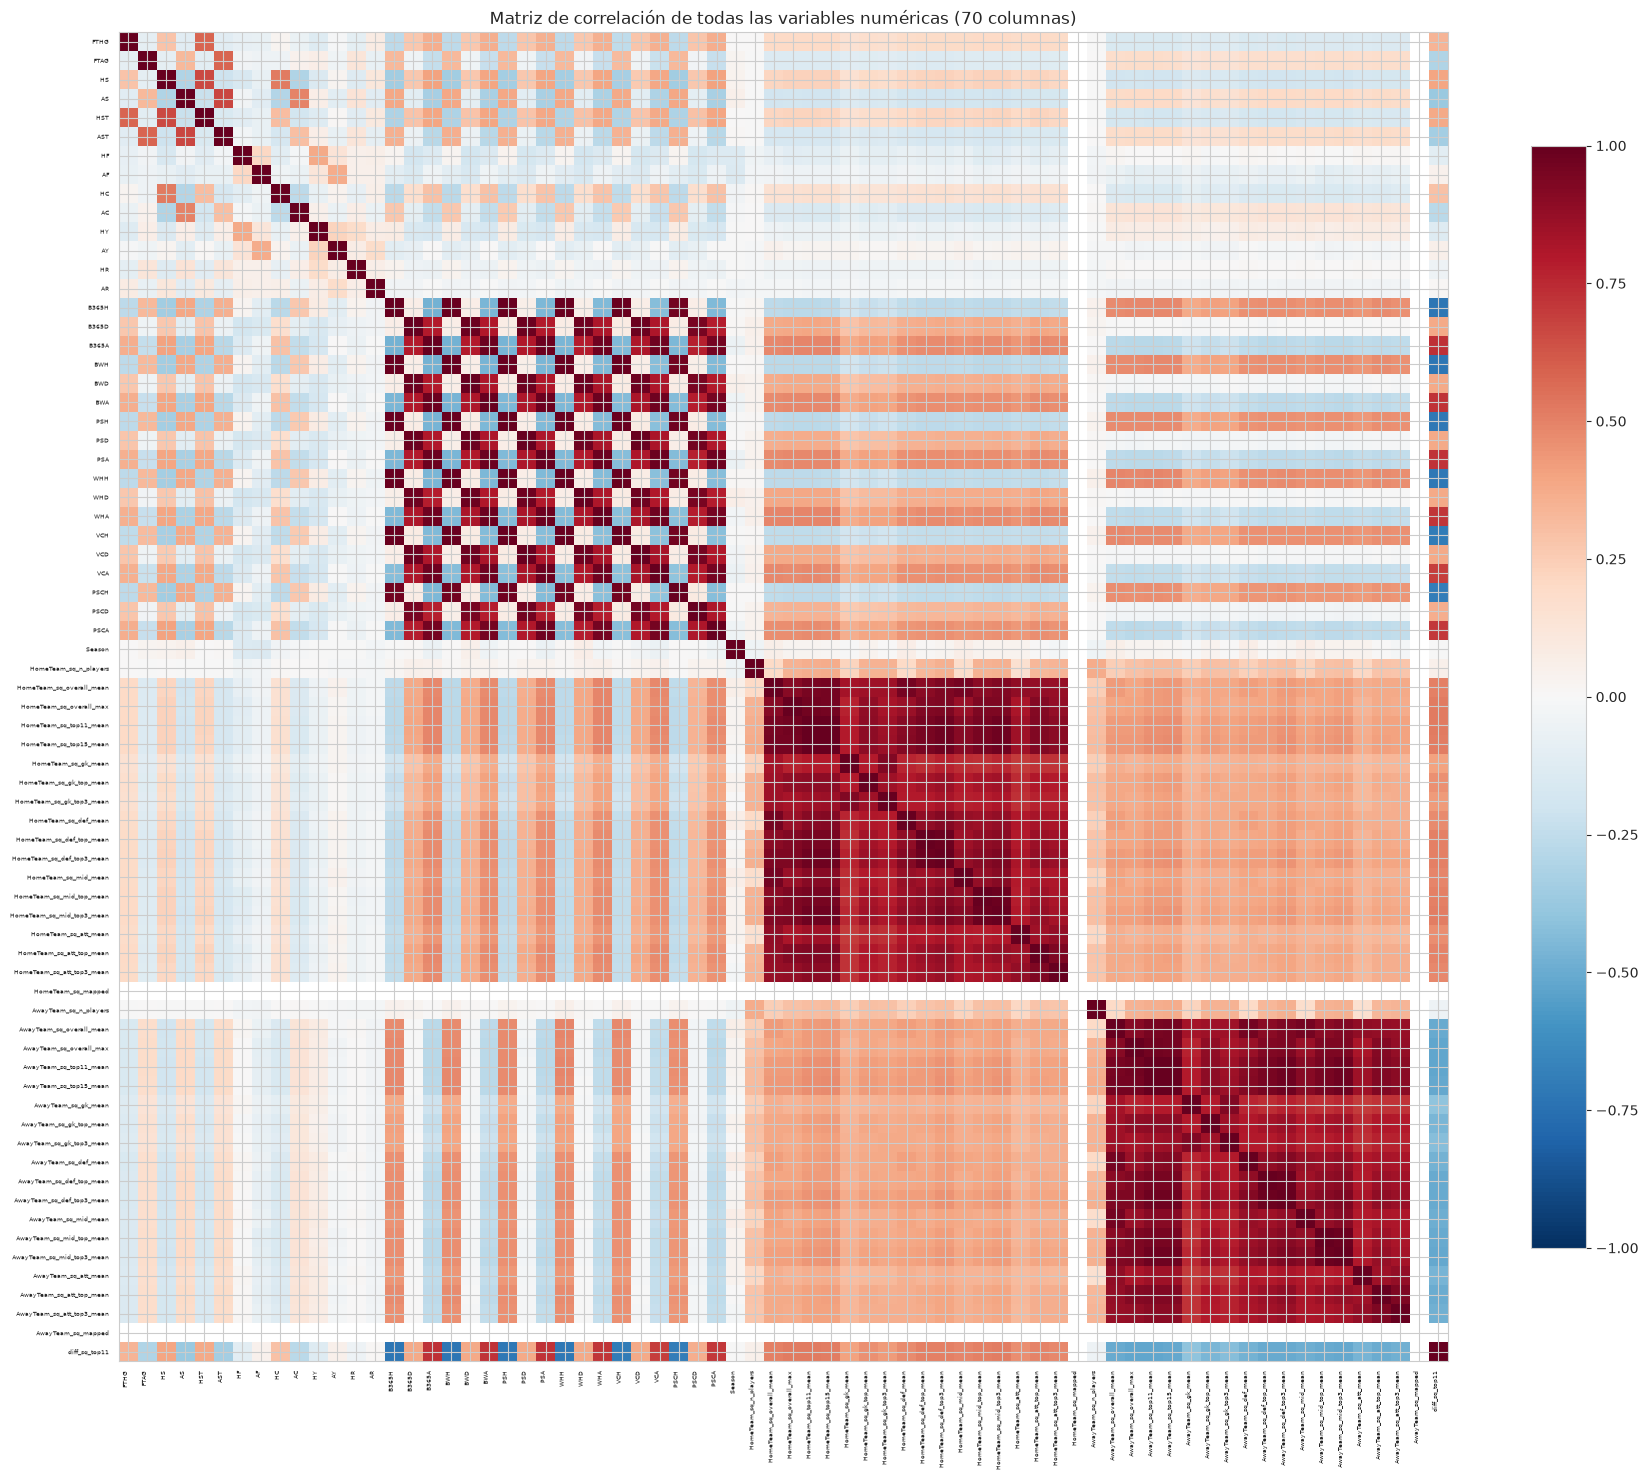

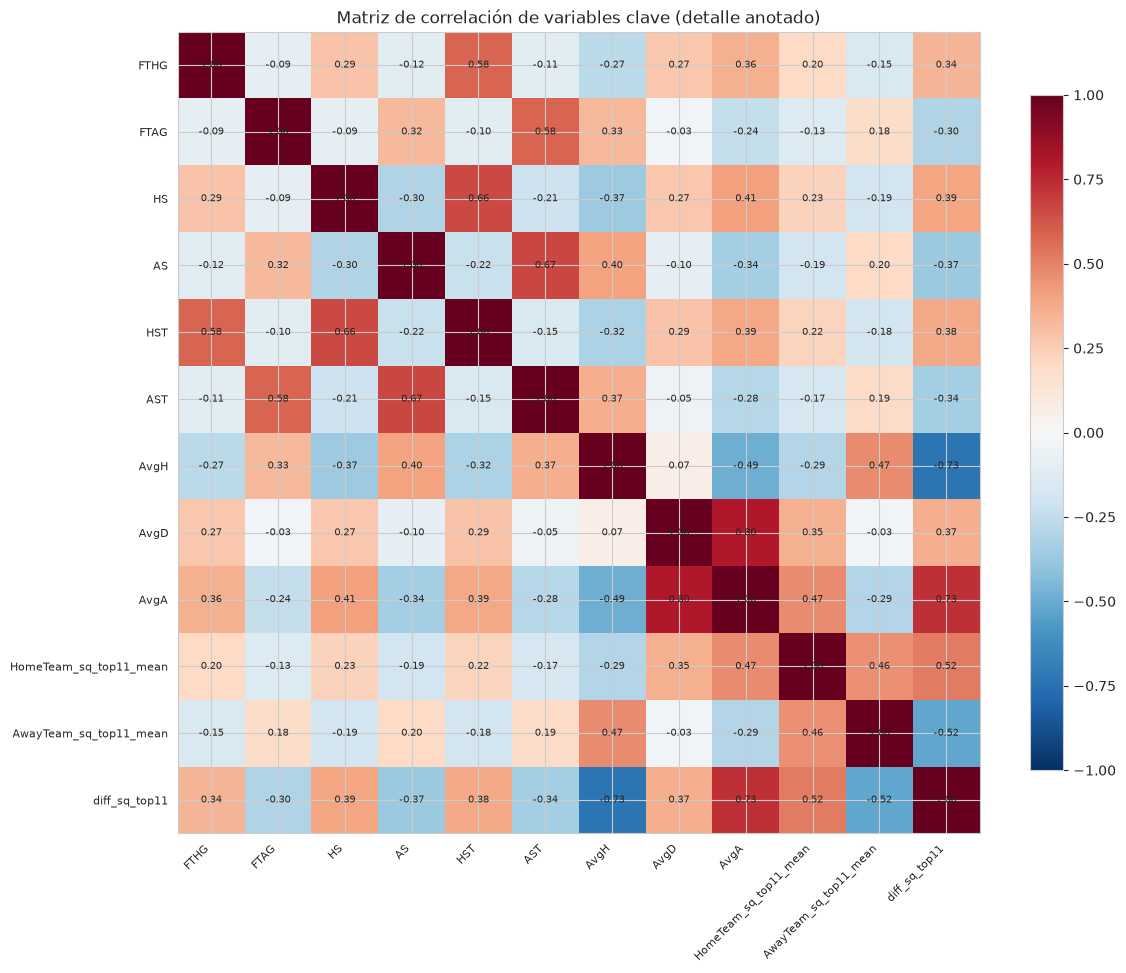

Columnas en la correlación total: 70


In [103]:
# 1) Correlación de TODAS las variables numéricas (mapa de color, sin anotaciones)
corr_total = df_clean.select_dtypes(include=[np.number]).corr()

fig, ax = plt.subplots(figsize=(18, 15))
im = ax.imshow(corr_total, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_total))); ax.set_xticklabels(corr_total.columns, rotation=90, ha='right', fontsize=4)
ax.set_yticks(range(len(corr_total))); ax.set_yticklabels(corr_total.columns, fontsize=4)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title(f'Matriz de correlación de todas las variables numéricas ({len(corr_total)} columnas)')
plt.tight_layout()
plt.show()

# 2) Detalle anotado de las variables clave (legible) en la media de mercado, no las cuotas por casa
df_eda = df_clean.join(df[['AvgH', 'AvgD', 'AvgA']])
corr_var = ['FTHG', 'FTAG', 'HS', 'AS', 'HST', 'AST', 'AvgH', 'AvgD', 'AvgA',
            'HomeTeam_sq_top11_mean', 'AwayTeam_sq_top11_mean', 'diff_sq_top11', 'Time_hora']
corr_var = [c for c in corr_var if c in df_eda.columns]
corr = df_eda[corr_var].corr()

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
for a in range(len(corr)):
    for b in range(len(corr)):
        ax.text(b, a, f'{corr.iloc[a, b]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Matriz de correlación de variables clave (detalle anotado)')
plt.tight_layout()
plt.show()

print('Columnas en la correlación total:', len(corr_total))

**Lo que se observa:** las cuotas de distintas casas/momentos correlacionan muy alto
(|r| > 0.9), lo que justifica, en la ingeniería de features, construir un consenso
del mercado (`MKT_pH/pD/pA`, probabilidades implícitas promedio de B365/BW/PS/WH) como referencia única.
Goles y tiros correlacionan positivamente (r ≈ 0.6–0.7) y la squad correlaciona poco con las cuotas →
señal complementaria.

## Análisis Multivariado (exploración)

Cerramos el análisis exploratorio mirando **varias variables a la vez**: un scatter matrix de las
variables clave coloreadas por `FTR` y una PCA sobre las cuotas medias de mercado para visualizar la
estructura del mercado frente al resultado.

Vamos a construir un **scatter matrix** (pares de variables) de goles, cuotas medias
y squad, coloreando cada punto según el resultado `FTR`: así vemos la separación conjunta de las tres
clases. Para que sea legible muestreamos 5000 partidos.

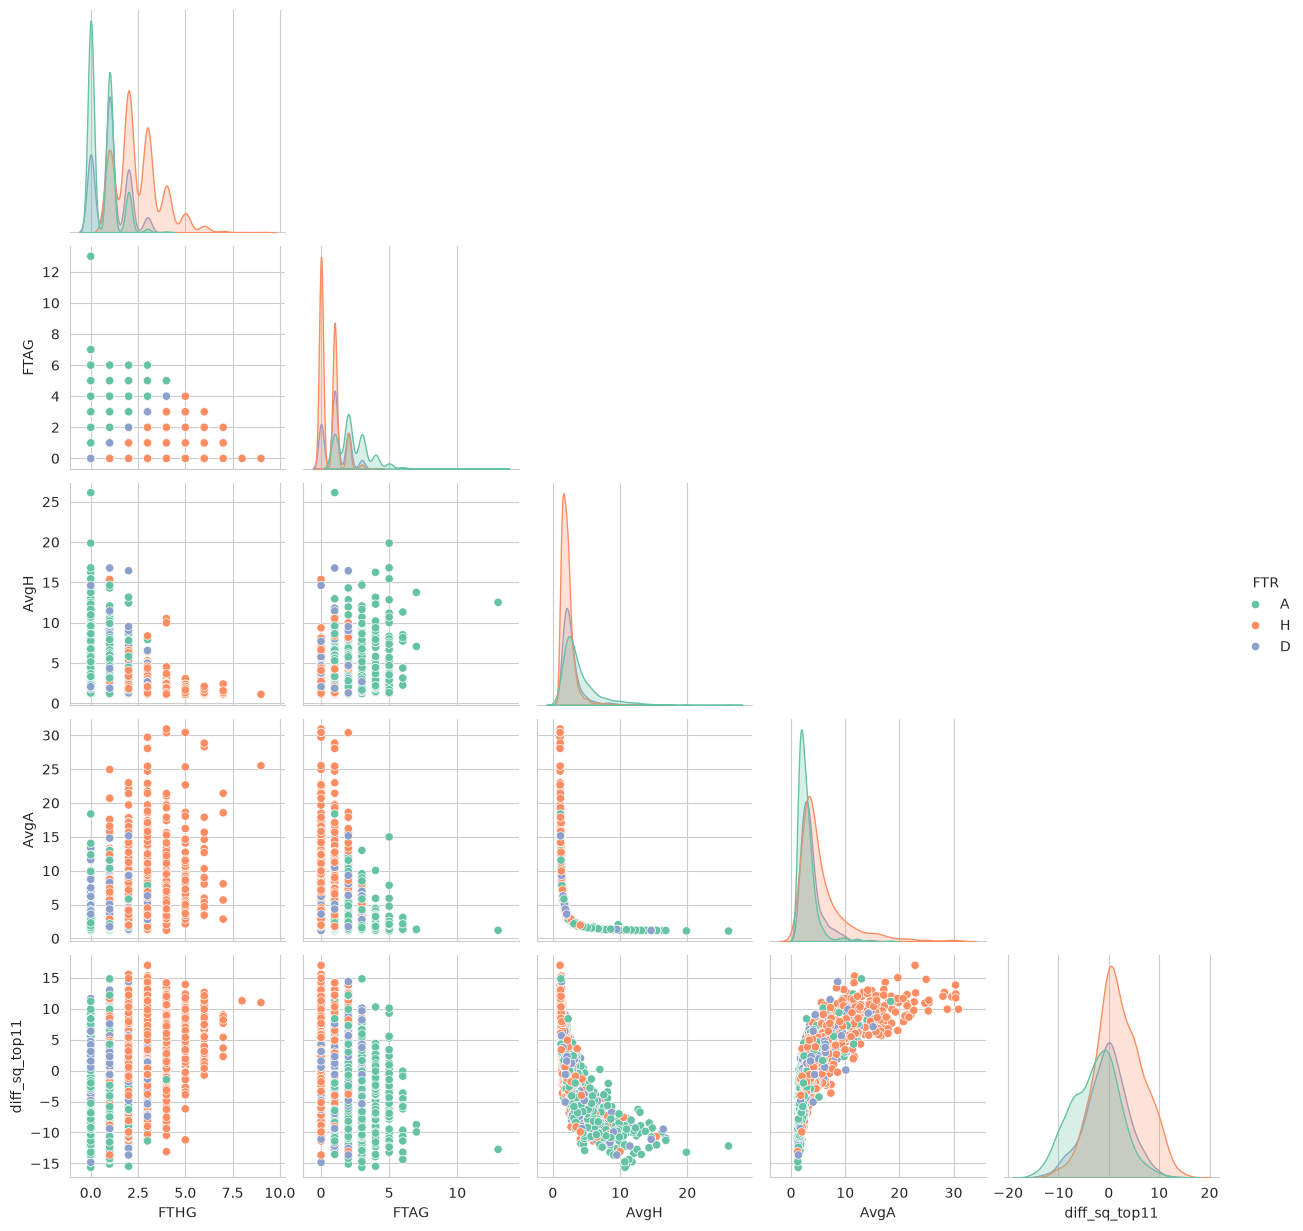

In [104]:
df_eda = df_clean.join(df[['AvgH', 'AvgD', 'AvgA']])

sns.pairplot(
    df_eda[['FTHG', 'FTAG', 'AvgH', 'AvgA', 'diff_sq_top11']].assign(FTR=df_eda['FTR']).sample(5000, random_state=42),
    hue='FTR', palette='Set2', diag_kind='kde', corner=True)
plt.show()

**Lo que se observa:** las clases se solapan bastante (el fútbol es ruidoso), pero los
pares `FTHG`/`FTAG` con `AvgA`/`AvgH` muestran la mejor separación parcial; la squad (`diff_sq_top11`)
aporta fronteras más difusas.

Ahora una **PCA sobre las cuotas medias de mercado** (variables altamente
correlacionadas) para comprimir el mercado en 2 componentes y ver si el resultado se estructura a lo
largo de ellas.

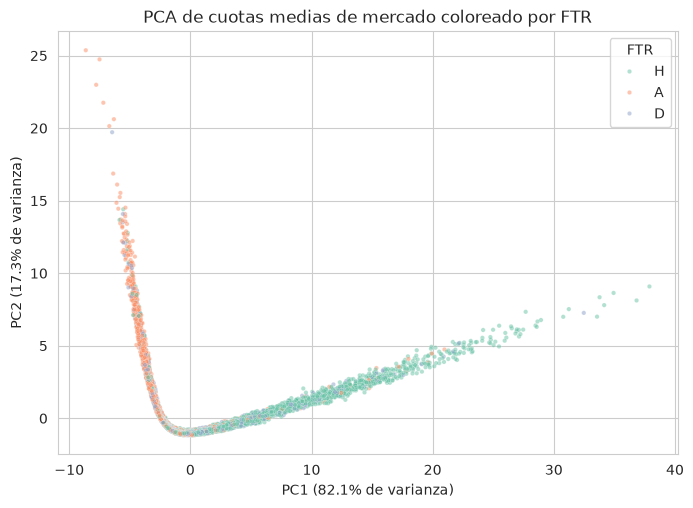

Varianza explicada: [82.1 17.3]


In [105]:
from sklearn.decomposition import PCA

Xp = df[['AvgH', 'AvgD', 'AvgA']].dropna()
pca = PCA(n_components=2, random_state=42)
pc = pca.fit_transform(Xp)

plt.figure(figsize=(8, 5.5))
sns.scatterplot(x=pc[:, 0], y=pc[:, 1],
                hue=df_clean.loc[Xp.index, 'FTR'], palette='Set2', alpha=0.5, s=10)
plt.title('PCA de cuotas medias de mercado coloreado por FTR')
plt.xlabel(f'PC1 ({100 * pca.explained_variance_ratio_[0]:.1f}% de varianza)')
plt.ylabel(f'PC2 ({100 * pca.explained_variance_ratio_[1]:.1f}% de varianza)')
plt.legend(title='FTR')
plt.show()

print('Varianza explicada:', (pca.explained_variance_ratio_ * 100).round(1))

**Lo que se observa:** los dos primeros componentes explican prácticamente toda la
varianza del mercado 1X2 (las cuotas son casi colineales, evidencia de multicolinealidad). Los
partidos con cuota de local muy baja (favorito claro, extremo de PC1) se concentran en victorias
locales; la nube central corresponde a partidos equilibrados y empates.

## Figuras para el informe

**Qué vamos a hacer.** Generar y guardar en `docs/figures/` las figuras que usa `docs/informe.tex`, a partir de los datos actuales (36,150 partidos, 12 temporadas). Las figuras anteriores correspondían a la versión de 30,182 partidos.

| Archivo | Contenido |
|---|---|
| `eda_nulos_cuotas.png` | Porcentaje de nulos de cada columna de cuotas, con los umbrales de 20% y 40% |
| `eda_nulos_otras.png` | Nulos de las demás columnas (estadísticas, árbitro, hora, plantilla) |
| `eda_boxplot_repr.png`, `eda_hist_repr.png` | Variables representativas con vallas IQR (valores observados, sin imputar) |
| `eda_cuotas_vs_ftr.png` | Cuotas de apertura de Bet365 según el resultado |
| `eda_squad_vs_ftr.png` | Diferencia de calidad del once según el resultado |
| `eda_corr_completa.png`, `eda_corr_detalle.png` | Matriz de correlación completa y de variables clave |

**Por qué.** Las figuras que usa el informe deben provenir del mismo código y de los mismos datos que las cifras que cita.

In [106]:
from pathlib import Path
FIG = Path('../../docs/figures'); FIG.mkdir(parents=True, exist_ok=True)
sns.set_style('whitegrid')

base = ['Div', 'Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF',
        'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'Time', 'Season', 'HFKC', 'AFKC']
sq_cols_ = [c for c in df.columns if '_sq_' in c]
unn = [c for c in df.columns if c.startswith('Unnamed')]
odds_cols = [c for c in df.columns if c not in base + sq_cols_ + unn]
n = len(df)

# 1) nulos de cuotas
nn = (df[odds_cols].isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(range(len(nn)), nn.values, color='salmon', width=1.0)
ax.axhline(40, color='k', ls='--', lw=1, label='40%'); ax.axhline(20, color='gray', ls=':', lw=1, label='20% (se eliminan las que lo superan)')
ax.set_xlabel(f'Columnas de cuotas ({len(nn)} con al menos un nulo, ordenadas)'); ax.set_ylabel('% de nulos'); ax.set_xticks([]); ax.legend(); ax.set_ylim(0, 102)
fig.tight_layout(); fig.savefig(FIG / 'eda_nulos_cuotas.png', dpi=200); plt.close(fig)
print('cuotas con nulos:', len(nn), '| >40%:', int((nn > 40).sum()), '| 20-40%:', int(((nn > 20) & (nn <= 40)).sum()), '| <=20%:', int((nn <= 20).sum()))

# 2) nulos de las demas columnas
otras = [c for c in df.columns if c not in odds_cols]
no = (df[otras].isna().mean() * 100); no = no[no > 0].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(range(len(no)), no.values, color='steelblue')
ax.set_xticks(range(len(no))); ax.set_xticklabels(no.index, rotation=75, ha='right', fontsize=7); ax.set_ylabel('% de nulos')
fig.tight_layout(); fig.savefig(FIG / 'eda_nulos_otras.png', dpi=200); plt.close(fig)
print('otras columnas con nulos:', no.round(1).head(8).to_dict())

# 3) variables representativas (valores observados)
REP = ['FTHG', 'FTAG', 'HS', 'AS', 'B365H', 'B365D', 'B365A', 'HomeTeam_sq_top11_mean', 'AwayTeam_sq_top11_mean']
def iqr(s):
    q1, q3 = s.quantile(.25), s.quantile(.75); return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
fig, axes = plt.subplots(3, 3, figsize=(10, 6.5))
for ax, c in zip(axes.ravel(), REP):
    s = df[c].dropna(); lo, hi = iqr(s)
    ax.boxplot(s, orientation='horizontal', showfliers=True, flierprops=dict(markersize=2))
    ax.set_title(f'{c} | outliers IQR = {int(((s < lo) | (s > hi)).sum())}', fontsize=8); ax.tick_params(labelsize=7)
fig.tight_layout(); fig.savefig(FIG / 'eda_boxplot_repr.png', dpi=200); plt.close(fig)
fig, axes = plt.subplots(3, 3, figsize=(10, 6.5))
for ax, c in zip(axes.ravel(), REP):
    s = df[c].dropna(); lo, hi = iqr(s)
    ax.hist(s, bins=30, color='#0072B2', edgecolor='white')
    ax.axvline(lo, color='red', ls='--', lw=1); ax.axvline(hi, color='red', ls='--', lw=1); ax.axvline(s.median(), color='k', ls=':', lw=1)
    ax.set_title(f'{c} | [{lo:.1f}, {hi:.1f}]', fontsize=8); ax.tick_params(labelsize=7)
fig.tight_layout(); fig.savefig(FIG / 'eda_hist_repr.png', dpi=200); plt.close(fig)

# 4) cuotas vs resultado
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, c in zip(axes, ['B365H', 'B365D', 'B365A']):
    sns.boxplot(data=df_clean, x='FTR', y=c, order=['H', 'D', 'A'], ax=ax, fliersize=1.5)
    ax.set_title(f'{c} segun FTR', fontsize=9)
fig.tight_layout(); fig.savefig(FIG / 'eda_cuotas_vs_ftr.png', dpi=200); plt.close(fig)
print('cuota media (B365) por resultado:'); print(df_clean.groupby('FTR')[['B365H', 'B365D', 'B365A']].mean().round(2).to_string())

# 5) plantilla vs resultado
df_clean['diff_sq_top11'] = df_clean['HomeTeam_sq_top11_mean'] - df_clean['AwayTeam_sq_top11_mean']
fig, ax = plt.subplots(figsize=(5.5, 3.6))
sns.boxplot(data=df_clean, x='FTR', y='diff_sq_top11', order=['H', 'D', 'A'], ax=ax, fliersize=1.5)
ax.axhline(0, color='red', ls='--', lw=1); ax.set_ylabel('top11 local - top11 visitante')
fig.tight_layout(); fig.savefig(FIG / 'eda_squad_vs_ftr.png', dpi=200); plt.close(fig)
print('diferencia de plantilla media por resultado:', df_clean.groupby('FTR').diff_sq_top11.mean().round(2).to_dict())

# 6) correlaciones
num = df_clean.select_dtypes(include=[np.number])
cc = num.corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cc, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cc))); ax.set_xticklabels(cc.columns, rotation=90, fontsize=4); ax.set_yticks(range(len(cc))); ax.set_yticklabels(cc.columns, fontsize=4)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title(f'Correlacion de las {len(cc)} variables numericas', fontsize=9)
fig.tight_layout(); fig.savefig(FIG / 'eda_corr_completa.png', dpi=200); plt.close(fig)
KEY = ['FTHG', 'FTAG', 'HS', 'AS', 'HST', 'AST', 'B365H', 'B365D', 'B365A', 'PSCH', 'HomeTeam_sq_top11_mean', 'AwayTeam_sq_top11_mean', 'diff_sq_top11']
ck = df_clean[KEY].corr()
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.imshow(ck, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(ck))); ax.set_xticklabels(ck.columns, rotation=60, ha='right', fontsize=8); ax.set_yticks(range(len(ck))); ax.set_yticklabels(ck.columns, fontsize=8)
for a in range(len(ck)):
    for b in range(len(ck)):
        ax.text(b, a, f'{ck.iloc[a, b]:.2f}', ha='center', va='center', fontsize=6)
fig.tight_layout(); fig.savefig(FIG / 'eda_corr_detalle.png', dpi=200); plt.close(fig)
iu = np.triu_indices(len(ck), 1)
print('correlacion entre cuotas B365 H/A:', round(float(ck.loc['B365H', 'B365A']), 2), '| B365H vs PSCH:', round(float(ck.loc['B365H', 'PSCH']), 3))
print('figuras guardadas en', FIG.resolve())

cuotas con nulos: 159 | >40%: 138 | 20-40%: 3 | <=20%: 18
otras columnas con nulos: {'Unnamed: 105': 100.0, 'Unnamed: 120': 100.0, 'Unnamed: 119': 100.0, 'AFKC': 98.7, 'HFKC': 98.7, 'Referee': 87.4, 'Time': 41.3, 'AF': 11.0}
cuota media (B365) por resultado:
     B365H  B365D  B365A
FTR                     
A     3.77   3.87   2.95
D     2.67   3.77   3.89
H     2.11   4.32   5.85
diferencia de plantilla media por resultado: {'A': -2.58, 'D': -0.33, 'H': 1.97}
correlacion entre cuotas B365 H/A: -0.47 | B365H vs PSCH: 0.963
figuras guardadas en /home/evssz/UTEC/6to/machine/ML_Project/docs/figures


**Hallazgo.** Las ocho figuras se regeneraron con los datos actuales.

- **Cuotas:** de las 159 columnas de cuotas, 138 superan el 40% de nulos, 3 están entre el 20% y el 40%, y 18 tienen hasta 20%.
- **Valores representativos:** los outliers de goles, tiros y cuotas largas son valores reales (partidos muy desequilibrados), no errores de captura.
- **Cuotas vs resultado:** la cuota del local es menor en las victorias locales y la del visitante en las visitantes; la diferencia de plantilla es positiva cuando gana el local.

**Decisión.** Las figuras de `docs/figures/` quedan sincronizadas con el notebook; si cambian los datos, se regeneran ejecutando esta celda.